In [1]:
# ==========================================================
# Stage 7 – Step 1.1 : Imports
# ==========================================================

from pathlib import Path
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision.models as models
import timm

print("=" * 70)
print("Stage 7 - Final Inference and Demo")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("OpenCV  :", cv2.__version__)
print("timm    :", timm.__version__)

Stage 7 - Final Inference and Demo
PyTorch : 2.10.0
OpenCV  : 4.13.0
timm    : 1.0.25


In [2]:
# ==========================================================
# Stage 7 – Step 1.2 : Device Configuration
# ==========================================================

if torch.backends.mps.is_available():

    device = torch.device("mps")
    device_name = "Apple Silicon GPU (MPS)"

elif torch.cuda.is_available():

    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

else:

    device = torch.device("cpu")
    device_name = "CPU"


print("=" * 70)
print("Device Configuration")
print("=" * 70)

print("Device      :", device)
print("Description :", device_name)

Device Configuration
Device      : mps
Description : Apple Silicon GPU (MPS)


In [3]:
# ==========================================================
# Stage 7 – Step 1.3 : Project Paths
# ==========================================================

project_root = (
    Path.home()
    / "Desktop"
    / "Mtech_final_project"
    / "SegFusionFormer"
)

dataset_dir = project_root / "dataset"

images_dir = dataset_dir / "images"
lung_masks_dir = dataset_dir / "lung_masks"

models_dir = project_root / "models"

results_dir = project_root / "results"
tables_dir = results_dir / "tables"
figures_dir = results_dir / "figures"

demo_dir = results_dir / "demo"

demo_figures_dir = (
    demo_dir
    / "figures"
)

demo_reports_dir = (
    demo_dir
    / "reports"
)

demo_figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

demo_reports_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ----------------------------------------------------------
# Trained models
# ----------------------------------------------------------

unet_path = (
    models_dir
    / "best_unet.pth"
)

classifier_path = (
    models_dir
    / "best_segfusionformer.pth"
)

# ----------------------------------------------------------
# Threshold file
# ----------------------------------------------------------

threshold_path = (
    tables_dir
    / "optimal_thresholds.csv"
)

print("=" * 70)
print("Final Inference Paths")
print("=" * 70)

print("Project Root       :", project_root)
print("Images             :", images_dir)
print("Lung Masks         :", lung_masks_dir)
print("U-Net              :", unet_path)
print("SegFusionFormer    :", classifier_path)
print("Thresholds         :", threshold_path)
print("Demo Figures       :", demo_figures_dir)
print("Demo Reports       :", demo_reports_dir)

Final Inference Paths
Project Root       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Images             : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Lung Masks         : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks
U-Net              : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth
SegFusionFormer    : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth
Thresholds         : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/optimal_thresholds.csv
Demo Figures       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures
Demo Reports       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports


In [4]:
# ==========================================================
# Stage 7 – Step 1.4 : Required File Verification
# ==========================================================

required_files = {

    "U-Net checkpoint":
        unet_path.exists(),

    "SegFusionFormer checkpoint":
        classifier_path.exists(),

    "Optimal thresholds":
        threshold_path.exists(),

    "NIH image folder":
        images_dir.exists()
}

print("=" * 70)
print("Required File Verification")
print("=" * 70)

for name, status in required_files.items():

    icon = "✅" if status else "❌"

    print(
        f"{icon} {name:30s}: {status}"
    )

if all(required_files.values()):

    print(
        "\n✅ Final inference environment is ready."
    )

else:

    print(
        "\n⚠️ One or more required files are missing."
    )

Required File Verification
✅ U-Net checkpoint              : True
✅ SegFusionFormer checkpoint    : True
✅ Optimal thresholds            : True
✅ NIH image folder              : True

✅ Final inference environment is ready.


In [5]:
# ==========================================================
# Stage 7 – Step 1.5 : Disease Classes
# ==========================================================

DISEASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

print("=" * 70)
print("Disease Classes")
print("=" * 70)

for i, disease in enumerate(
    DISEASES,
    start=1
):

    print(
        f"{i:2d}. {disease}"
    )

print(
    "\nNumber of Classes :",
    len(DISEASES)
)

Disease Classes
 1. Atelectasis
 2. Cardiomegaly
 3. Effusion
 4. Infiltration
 5. Mass
 6. Nodule
 7. Pneumonia
 8. Pneumothorax
 9. Consolidation
10. Edema
11. Emphysema
12. Fibrosis
13. Pleural_Thickening
14. Hernia

Number of Classes : 14


In [6]:
# ==========================================================
# Stage 7 – Step 1.6 : Load Optimized Thresholds
# ==========================================================

threshold_df = pd.read_csv(
    threshold_path
)

optimal_thresholds = (
    threshold_df["Threshold"]
    .values
    .astype(np.float32)
)

print("=" * 70)
print("Optimized Thresholds Loaded")
print("=" * 70)

display(
    threshold_df.round(4)
)

print(
    "\nThreshold Count :",
    len(optimal_thresholds)
)

Optimized Thresholds Loaded


,Disease,Threshold
0,Atelectasis,0.6505
1,Cardiomegaly,0.9719
2,Effusion,0.7342
3,Infiltration,0.5163
4,Mass,0.8488
5,Nodule,0.7462
6,Pneumonia,0.8156
7,Pneumothorax,0.8748
8,Consolidation,0.7302
9,Edema,0.9483



Threshold Count : 14


In [7]:
# ==========================================================
# Stage 7 – Step 2.1 : Rebuild U-Net
# ==========================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x1, x2):

        x1 = self.up(x1)

        if x1.shape[2:] != x2.shape[2:]:

            x1 = F.interpolate(
                x1,
                size=x2.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat(
            [x2, x1],
            dim=1
        )

        return self.conv(x)


class UNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=1
    ):
        super().__init__()

        self.inc = DoubleConv(
            in_channels,
            32
        )

        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)
        self.down4 = Down(256, 512)

        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)
        self.up4 = Up(64, 32)

        self.outc = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.outc(x)


print("✅ U-Net architecture rebuilt.")

✅ U-Net architecture rebuilt.


In [8]:
# ==========================================================
# Stage 7 – Step 2.2 : Load Best U-Net
# ==========================================================

unet_model = UNet(
    in_channels=1,
    out_channels=1
).to(device)

unet_checkpoint = torch.load(
    unet_path,
    map_location=device
)

if (
    isinstance(unet_checkpoint, dict)
    and "model_state_dict" in unet_checkpoint
):

    unet_model.load_state_dict(
        unet_checkpoint["model_state_dict"]
    )

else:

    unet_model.load_state_dict(
        unet_checkpoint
    )

unet_model.eval()

print("=" * 70)
print("U-Net Loaded Successfully")
print("=" * 70)

print(
    "Device :",
    next(unet_model.parameters()).device
)

if isinstance(unet_checkpoint, dict):

    print(
        "Validation Dice :",
        unet_checkpoint.get(
            "val_dice",
            "Not stored"
        )
    )

    print(
        "Validation Loss :",
        unet_checkpoint.get(
            "val_loss",
            "Not stored"
        )
    )

U-Net Loaded Successfully
Device : mps:0
Validation Dice : 0.9600503588544911
Validation Loss : 0.10720872776261692


In [9]:
# ==========================================================
# Stage 7 – Step 2.3 : Mask-Guided Attention
# ==========================================================

class MaskGuidedAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.attention_generator = nn.Sequential(

            nn.Conv2d(
                2,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                8,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                8,
                1,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

        self.alpha = nn.Parameter(
            torch.tensor(1.0)
        )

    def forward(self, x):

        image = x[:, 0:1]

        mask = x[:, 1:2]

        learned_attention = (
            self.attention_generator(x)
        )

        guided_attention = (
            learned_attention * mask
        )

        enhanced_image = image * (
            1.0
            +
            self.alpha * guided_attention
        )

        enhanced_image = torch.clamp(
            enhanced_image,
            0.0,
            1.0
        )

        enhanced_rgb = enhanced_image.repeat(
            1,
            3,
            1,
            1
        )

        return (
            enhanced_rgb,
            guided_attention
        )

In [10]:
# ==========================================================
# Stage 7 – Step 2.4 : Feature Extraction Branches
# ==========================================================

class EfficientNetBranch(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = models.efficientnet_b0(
            weights=None
        )

        self.features = backbone.features

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.feature_dim = 1280

    def forward(self, x):

        x = self.features(x)

        x = self.pool(x)

        x = torch.flatten(
            x,
            1
        )

        return x


class MaxViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "maxvit_tiny_tf_224.in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )

        self.feature_dim = (
            self.backbone.num_features
        )

    def forward(self, x):

        return self.backbone(x)

In [11]:
# ==========================================================
# Stage 7 – Step 2.5 : Adaptive Feature Fusion
# ==========================================================

class AdaptiveFeatureFusion(nn.Module):

    def __init__(
        self,
        cnn_dim,
        maxvit_dim,
        fusion_dim=512,
        dropout=0.3
    ):

        super().__init__()

        self.cnn_projection = nn.Sequential(

            nn.Linear(
                cnn_dim,
                fusion_dim
            ),

            nn.ReLU(inplace=True)
        )

        self.maxvit_projection = nn.Sequential(

            nn.Linear(
                maxvit_dim,
                fusion_dim
            ),

            nn.ReLU(inplace=True)
        )

        self.gate = nn.Sequential(

            nn.Linear(
                fusion_dim * 2,
                fusion_dim
            ),

            nn.ReLU(inplace=True),

            nn.Linear(
                fusion_dim,
                2
            ),

            nn.Softmax(dim=1)
        )

        self.refine = nn.Sequential(

            nn.LayerNorm(
                fusion_dim
            ),

            nn.Dropout(
                dropout
            )
        )

    def forward(
        self,
        cnn_features,
        maxvit_features
    ):

        cnn_proj = self.cnn_projection(
            cnn_features
        )

        maxvit_proj = self.maxvit_projection(
            maxvit_features
        )

        combined = torch.cat(
            [
                cnn_proj,
                maxvit_proj
            ],
            dim=1
        )

        weights = self.gate(
            combined
        )

        cnn_weight = weights[:, 0:1]

        maxvit_weight = weights[:, 1:2]

        fused = (
            cnn_weight * cnn_proj
            +
            maxvit_weight * maxvit_proj
        )

        fused = self.refine(
            fused
        )

        return fused, weights

In [12]:
# ==========================================================
# Stage 7 – Step 2.6 : Complete SegFusionFormer
# ==========================================================

class SegFusionFormer(nn.Module):

    def __init__(
        self,
        num_classes=14
    ):

        super().__init__()

        self.mask_attention = (
            MaskGuidedAttention()
        )

        self.cnn_branch = (
            EfficientNetBranch()
        )

        self.maxvit_branch = (
            MaxViTBranch()
        )

        self.fusion = AdaptiveFeatureFusion(

            cnn_dim=
                self.cnn_branch.feature_dim,

            maxvit_dim=
                self.maxvit_branch.feature_dim,

            fusion_dim=512,

            dropout=0.3
        )

        self.classifier = nn.Sequential(

            nn.LayerNorm(512),

            nn.Linear(
                512,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                256,
                128
            ),

            nn.GELU(),

            nn.Dropout(0.2),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        enhanced_image, attention_map = (
            self.mask_attention(x)
        )

        cnn_features = (
            self.cnn_branch(
                enhanced_image
            )
        )

        maxvit_features = (
            self.maxvit_branch(
                enhanced_image
            )
        )

        fused_features, fusion_weights = (
            self.fusion(
                cnn_features,
                maxvit_features
            )
        )

        logits = self.classifier(
            fused_features
        )

        return (
            logits,
            fusion_weights,
            attention_map
        )


print(
    "✅ SegFusionFormer architecture rebuilt."
)

✅ SegFusionFormer architecture rebuilt.


In [13]:
# ==========================================================
# Stage 7 – Step 2.7 : Load Best SegFusionFormer
# ==========================================================

best_model = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

classifier_checkpoint = torch.load(
    classifier_path,
    map_location=device
)

if (
    isinstance(classifier_checkpoint, dict)
    and
    "model_state_dict"
    in classifier_checkpoint
):

    best_model.load_state_dict(
        classifier_checkpoint[
            "model_state_dict"
        ]
    )

else:

    best_model.load_state_dict(
        classifier_checkpoint
    )

best_model.eval()

print("=" * 70)
print("SegFusionFormer Loaded Successfully")
print("=" * 70)

print(
    "Device :",
    next(
        best_model.parameters()
    ).device
)

print(
    "Classes:",
    len(DISEASES)
)

SegFusionFormer Loaded Successfully
Device : mps:0
Classes: 14


In [14]:
# ==========================================================
# Stage 7 – Step 2.8 : Verify Both Models
# ==========================================================

# ----------------------------------------------------------
# Test U-Net
# ----------------------------------------------------------

dummy_unet_input = torch.randn(
    1,
    1,
    256,
    256
).to(device)

with torch.no_grad():

    dummy_mask = unet_model(
        dummy_unet_input
    )


# ----------------------------------------------------------
# Test SegFusionFormer
# ----------------------------------------------------------

dummy_classifier_input = torch.randn(
    1,
    2,
    224,
    224
).to(device)

with torch.no_grad():

    logits, fusion_weights, attention_map = (
        best_model(
            dummy_classifier_input
        )
    )


print("=" * 70)
print("Final Model Verification")
print("=" * 70)

print("\nU-Net")
print("-----")

print(
    "Input  :",
    dummy_unet_input.shape
)

print(
    "Output :",
    dummy_mask.shape
)


print("\nSegFusionFormer")
print("----------------")

print(
    "Input           :",
    dummy_classifier_input.shape
)

print(
    "Logits          :",
    logits.shape
)

print(
    "Fusion Weights  :",
    fusion_weights.shape
)

print(
    "Attention Map   :",
    attention_map.shape
)

print("\nDevices")
print("-------")

print(
    "U-Net           :",
    next(unet_model.parameters()).device
)

print(
    "SegFusionFormer :",
    next(best_model.parameters()).device
)

print(
    "\n✅ Both trained models are ready for final inference."
)

Final Model Verification

U-Net
-----
Input  : torch.Size([1, 1, 256, 256])
Output : torch.Size([1, 1, 256, 256])

SegFusionFormer
----------------
Input           : torch.Size([1, 2, 224, 224])
Logits          : torch.Size([1, 14])
Fusion Weights  : torch.Size([1, 2])
Attention Map   : torch.Size([1, 1, 224, 224])

Devices
-------
U-Net           : mps:0
SegFusionFormer : mps:0

✅ Both trained models are ready for final inference.


In [15]:
# ==========================================================
# Stage 7 – Step 3.1 : Prepare Single X-ray for U-Net
# ==========================================================

def preprocess_for_unet(image_path):

    # Read chest X-ray in grayscale
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise RuntimeError(
            f"Unable to read image: {image_path}"
        )

    # Keep original for later visualization
    original_image = image.copy()

    # Resize to U-Net training size
    image_256 = cv2.resize(
        image,
        (256, 256)
    )

    # Normalize to [0, 1]
    image_256 = (
        image_256.astype(np.float32) / 255.0
    )

    # Convert to tensor:
    # [1, 1, 256, 256]
    unet_tensor = torch.from_numpy(
        image_256
    ).unsqueeze(0).unsqueeze(0)

    unet_tensor = unet_tensor.to(device)

    return (
        original_image,
        image_256,
        unet_tensor
    )


print("✅ U-Net preprocessing function created.")

✅ U-Net preprocessing function created.


In [16]:
# ==========================================================
# Stage 7 – Step 3.2 : Automatic U-Net Segmentation
# ==========================================================

def predict_lung_mask(
    image_path,
    unet_model,
    device,
    threshold=0.5
):

    (
        original_image,
        image_256,
        unet_tensor
    ) = preprocess_for_unet(
        image_path
    )

    unet_model.eval()

    with torch.no_grad():

        mask_logits = unet_model(
            unet_tensor
        )

        mask_probability = torch.sigmoid(
            mask_logits
        )

        predicted_mask = (
            mask_probability >= threshold
        ).float()

    predicted_mask = (
        predicted_mask[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    return (
        original_image,
        image_256,
        predicted_mask
    )


print("✅ Automatic lung segmentation function created.")

✅ Automatic lung segmentation function created.


In [17]:
# ==========================================================
# Stage 7 – Step 3.3 : Prepare SegFusionFormer Input
# ==========================================================

def prepare_classifier_input(
    original_image,
    predicted_mask
):

    # Resize X-ray to classifier size
    image_224 = cv2.resize(
        original_image,
        (224, 224)
    )

    # Resize mask to classifier size
    mask_224 = cv2.resize(
        predicted_mask,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image
    image_224 = (
        image_224.astype(np.float32)
        / 255.0
    )

    # Ensure binary mask
    mask_224 = (
        mask_224 > 0.5
    ).astype(np.float32)

    # Convert to tensors
    image_tensor = torch.from_numpy(
        image_224
    ).unsqueeze(0)

    mask_tensor = torch.from_numpy(
        mask_224
    ).unsqueeze(0)

    # Combine into 2-channel input
    classifier_tensor = torch.cat(
        [
            image_tensor,
            mask_tensor
        ],
        dim=0
    )

    # Add batch dimension
    classifier_tensor = (
        classifier_tensor
        .unsqueeze(0)
        .to(device)
    )

    return (
        classifier_tensor,
        image_224,
        mask_224
    )


print("✅ SegFusionFormer preprocessing function created.")

✅ SegFusionFormer preprocessing function created.


In [18]:
# ==========================================================
# Stage 7 – Step 3.4 : Complete Preprocessing Pipeline
# ==========================================================

def prepare_single_xray(
    image_path,
    unet_model,
    device
):

    # -----------------------------------------
    # Lung segmentation
    # -----------------------------------------

    (
        original_image,
        image_256,
        predicted_mask
    ) = predict_lung_mask(
        image_path=image_path,
        unet_model=unet_model,
        device=device
    )

    # -----------------------------------------
    # Classification preprocessing
    # -----------------------------------------

    (
        classifier_tensor,
        image_224,
        mask_224
    ) = prepare_classifier_input(
        original_image,
        predicted_mask
    )

    return {
        "original_image": original_image,
        "unet_image": image_256,
        "predicted_mask_256": predicted_mask,
        "image_224": image_224,
        "mask_224": mask_224,
        "classifier_tensor": classifier_tensor
    }


print("✅ Final single-X-ray preprocessing pipeline created.")

✅ Final single-X-ray preprocessing pipeline created.


In [22]:
# ==========================================================
# Stage 7 – Step 3.5 : Test Preprocessing Pipeline
# ==========================================================

test_images = sorted(
    images_dir.glob("*.png")
)

if len(test_images) == 0:
    raise RuntimeError(
        "No PNG images found in the NIH image folder."
    )

test_image_path = images_dir / "00000001_002.png"

if not test_image_path.exists():
    raise FileNotFoundError(test_image_path)

prepared = prepare_single_xray(
    image_path=test_image_path,
    unet_model=unet_model,
    device=device
)

print("=" * 70)
print("Single X-ray Preprocessing Test")
print("=" * 70)

print("Image :", test_image_path.name)

print(
    "Original Shape       :",
    prepared["original_image"].shape
)

print(
    "U-Net Image Shape    :",
    prepared["unet_image"].shape
)

print(
    "Mask 256 Shape       :",
    prepared["predicted_mask_256"].shape
)

print(
    "Classifier Image     :",
    prepared["image_224"].shape
)

print(
    "Classifier Mask      :",
    prepared["mask_224"].shape
)

print(
    "Classifier Tensor    :",
    prepared["classifier_tensor"].shape
)

print(
    "Mask Values          :",
    np.unique(
        prepared["mask_224"]
    )
)

Single X-ray Preprocessing Test
Image : 00000001_002.png
Original Shape       : (1024, 1024)
U-Net Image Shape    : (256, 256)
Mask 256 Shape       : (256, 256)
Classifier Image     : (224, 224)
Classifier Mask      : (224, 224)
Classifier Tensor    : torch.Size([1, 2, 224, 224])
Mask Values          : [0. 1.]


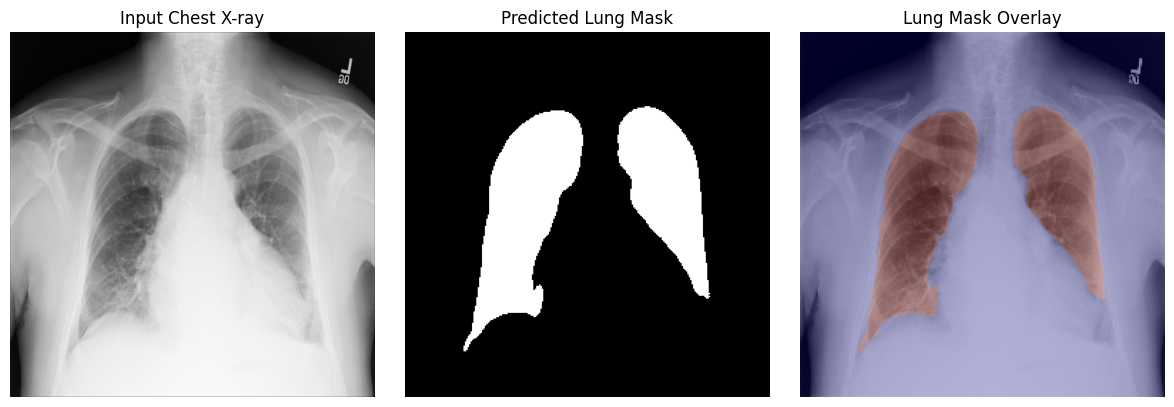

In [23]:
# ==========================================================
# Stage 7 – Step 3.6 : Visualize Preprocessing Result
# ==========================================================

plt.figure(
    figsize=(12, 4)
)

plt.subplot(1, 3, 1)

plt.imshow(
    prepared["original_image"],
    cmap="gray"
)

plt.title("Input Chest X-ray")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    prepared["predicted_mask_256"],
    cmap="gray"
)

plt.title("Predicted Lung Mask")
plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    prepared["image_224"],
    cmap="gray"
)

plt.imshow(
    prepared["mask_224"],
    cmap="jet",
    alpha=0.30
)

plt.title("Lung Mask Overlay")
plt.axis("off")


plt.tight_layout()
plt.show()

Image: 00000001_000.png
Minimum probability: 0.031579122
Maximum probability: 0.9954275
Mean probability: 0.094554044
Threshold 0.3: 4.70% pixels selected
Threshold 0.5: 4.17% pixels selected
Threshold 0.7: 3.71% pixels selected


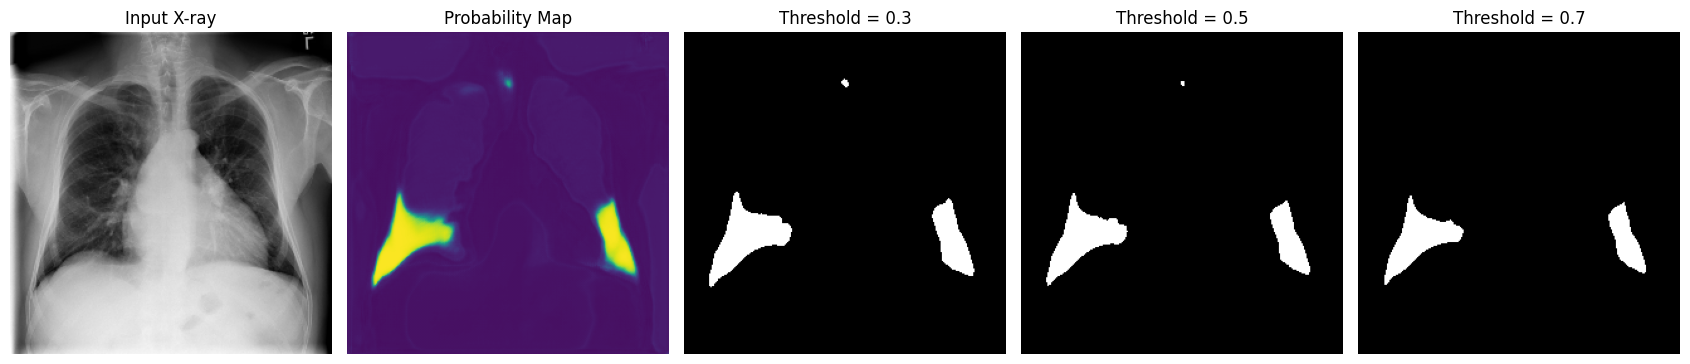

In [21]:
# ==========================================================
# Lung Segmentation Diagnostic
# ==========================================================

# Use the same X-ray selected in Step 3.5
original, image_256, input_tensor = preprocess_for_unet(
    test_image_path
)

unet_model.eval()

with torch.no_grad():
    logits = unet_model(input_tensor)

    probabilities = torch.sigmoid(logits)[0, 0]
    probabilities = probabilities.cpu().numpy()

print("Image:", test_image_path.name)
print("Minimum probability:", probabilities.min())
print("Maximum probability:", probabilities.max())
print("Mean probability:", probabilities.mean())

# Compare different segmentation thresholds
thresholds_to_test = [0.3, 0.5, 0.7]

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

axes[0].imshow(image_256, cmap="gray")
axes[0].set_title("Input X-ray")

axes[1].imshow(probabilities, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Probability Map")

for i, threshold in enumerate(thresholds_to_test):

    mask = (probabilities >= threshold).astype(np.float32)

    axes[i + 2].imshow(mask, cmap="gray")
    axes[i + 2].set_title(f"Threshold = {threshold}")

    print(
        f"Threshold {threshold}: "
        f"{100 * mask.mean():.2f}% pixels selected"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# ==========================================================
# Stage 7 – Step 4.1 : Final Disease Prediction Function
# ==========================================================

def predict_14_diseases(
    classifier,
    prepared_input,
    thresholds,
    diseases,
    device
):

    classifier.eval()

    classifier_tensor = prepared_input[
        "classifier_tensor"
    ].to(device)

    with torch.no_grad():

        logits, fusion_weights, attention_map = classifier(
            classifier_tensor
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    # ------------------------------------------------------
    # Apply optimized class-specific thresholds
    # ------------------------------------------------------

    predictions = (
        probabilities >= thresholds
    ).astype(np.int32)

    # ------------------------------------------------------
    # Build result table
    # ------------------------------------------------------

    rows = []

    for disease, probability, threshold, prediction in zip(
        diseases,
        probabilities,
        thresholds,
        predictions
    ):

        rows.append({
            "Disease": disease,
            "Probability": float(probability),
            "Threshold": float(threshold),
            "Prediction": int(prediction)
        })

    prediction_df = pd.DataFrame(
        rows
    )

    # Sort highest probability first
    prediction_df = prediction_df.sort_values(
        "Probability",
        ascending=False
    ).reset_index(drop=True)

    return {
        "table": prediction_df,
        "probabilities": probabilities,
        "predictions": predictions,
        "fusion_weights": (
            fusion_weights[0]
            .detach()
            .cpu()
            .numpy()
        ),
        "attention_map": (
            attention_map[0, 0]
            .detach()
            .cpu()
            .numpy()
        ),
        "logits": logits.detach().cpu()
    }


print("✅ Final disease prediction function created.")

✅ Final disease prediction function created.


In [25]:
# ==========================================================
# Stage 7 – Step 4.2 : Run SegFusionFormer Prediction
# ==========================================================

prediction_result = predict_14_diseases(
    classifier=best_model,
    prepared_input=prepared,
    thresholds=optimal_thresholds,
    diseases=DISEASES,
    device=device
)

prediction_table = prediction_result[
    "table"
]

print("=" * 75)
print("SegFusionFormer Disease Prediction")
print("=" * 75)

print(
    "Image :",
    test_image_path.name
)

print("\nAll 14 Disease Predictions")
print("-" * 75)

display(
    prediction_table.round(4)
)

SegFusionFormer Disease Prediction
Image : 00000001_002.png

All 14 Disease Predictions
---------------------------------------------------------------------------


,Disease,Probability,Threshold,Prediction
0,Cardiomegaly,0.9859,0.9719,1
1,Fibrosis,0.8456,0.8751,0
2,Hernia,0.8387,0.9997,0
3,Effusion,0.7415,0.7342,1
4,Pleural_Thickening,0.7179,0.8191,0
5,Atelectasis,0.6255,0.6505,0
6,Infiltration,0.5304,0.5163,1
7,Pneumonia,0.5232,0.8156,0
8,Consolidation,0.4085,0.7302,0
9,Nodule,0.3630,0.7462,0


In [26]:
# ==========================================================
# Stage 7 – Step 4.3 : Positive Disease Predictions
# ==========================================================

positive_predictions = prediction_table[
    prediction_table["Prediction"] == 1
].copy()

print("=" * 75)
print("Predicted Positive Diseases")
print("=" * 75)

if len(positive_predictions) == 0:

    print(
        "No disease exceeded its optimized threshold."
    )

else:

    display(
        positive_predictions[
            [
                "Disease",
                "Probability",
                "Threshold"
            ]
        ].round(4)
    )

Predicted Positive Diseases


,Disease,Probability,Threshold
0,Cardiomegaly,0.9859,0.9719
3,Effusion,0.7415,0.7342
6,Infiltration,0.5304,0.5163


In [27]:
# ==========================================================
# Stage 7 – Step 4.4 : Adaptive Fusion Weights
# ==========================================================

fusion_weights = prediction_result[
    "fusion_weights"
]

print("=" * 70)
print("Adaptive Feature Fusion")
print("=" * 70)

print(
    f"EfficientNet-B0 : {fusion_weights[0]:.4f}"
)

print(
    f"MaxViT          : {fusion_weights[1]:.4f}"
)

print(
    f"Weight Sum      : {fusion_weights.sum():.4f}"
)

Adaptive Feature Fusion
EfficientNet-B0 : 1.0000
MaxViT          : 0.0000
Weight Sum      : 1.0000


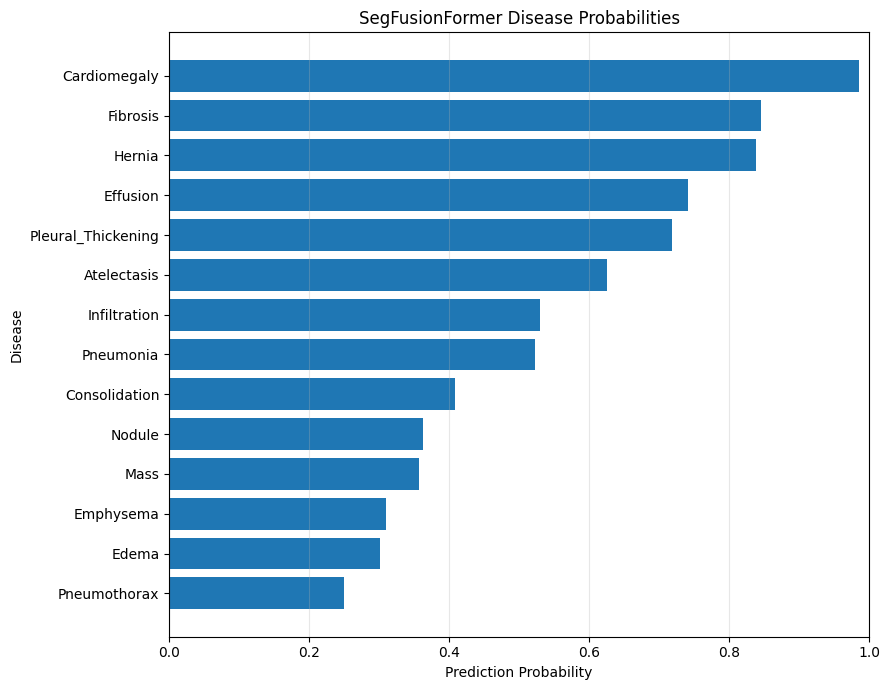

In [28]:
# ==========================================================
# Stage 7 – Step 4.5 : Disease Probability Plot
# ==========================================================

plot_df = prediction_table.sort_values(
    "Probability",
    ascending=True
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    plot_df["Disease"],
    plot_df["Probability"]
)

plt.xlabel(
    "Prediction Probability"
)

plt.ylabel(
    "Disease"
)

plt.title(
    "SegFusionFormer Disease Probabilities"
)

plt.xlim(
    0,
    1
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [29]:
# ==========================================================
# Stage 7 – Step 4.6 : Prediction Summary
# ==========================================================

print("=" * 75)
print("FINAL CLASSIFICATION SUMMARY")
print("=" * 75)

print(
    "Number of predicted positive diseases :",
    int(
        prediction_result[
            "predictions"
        ].sum()
    )
)

if len(positive_predictions) > 0:

    print("\nPredicted diseases:")

    for _, row in positive_predictions.iterrows():

        print(
            f" - {row['Disease']}: "
            f"{row['Probability']:.4f}"
        )

else:

    print(
        "\nNo positive disease prediction."
    )

print("=" * 75)

FINAL CLASSIFICATION SUMMARY
Number of predicted positive diseases : 3

Predicted diseases:
 - Cardiomegaly: 0.9859
 - Effusion: 0.7415
 - Infiltration: 0.5304


In [30]:
# ==========================================================
# Stage 7 – Step 5.1 : Extract Mask-Guided Attention
# ==========================================================

attention_map = prediction_result[
    "attention_map"
]

xray_image = prepared[
    "image_224"
]

lung_mask = prepared[
    "mask_224"
]

print("=" * 70)
print("Mask-Guided Attention Information")
print("=" * 70)

print("X-ray Shape     :", xray_image.shape)
print("Mask Shape      :", lung_mask.shape)
print("Attention Shape :", attention_map.shape)

print("\nAttention Range")
print(
    f"Min : {attention_map.min():.4f}"
)
print(
    f"Max : {attention_map.max():.4f}"
)

Mask-Guided Attention Information
X-ray Shape     : (224, 224)
Mask Shape      : (224, 224)
Attention Shape : (224, 224)

Attention Range
Min : 0.0000
Max : 0.0010


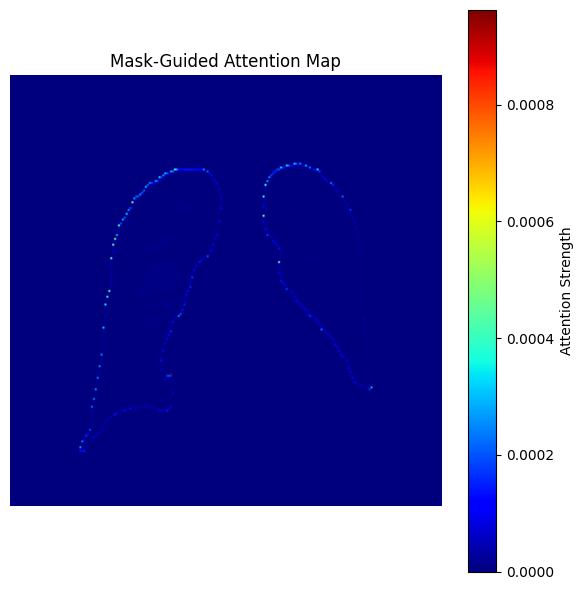

In [31]:
# ==========================================================
# Stage 7 – Step 5.2 : Raw Attention Map
# ==========================================================

plt.figure(figsize=(6, 6))

plt.imshow(
    attention_map,
    cmap="jet"
)

plt.title(
    "Mask-Guided Attention Map"
)

plt.axis("off")

plt.colorbar(
    label="Attention Strength"
)

plt.tight_layout()

plt.show()

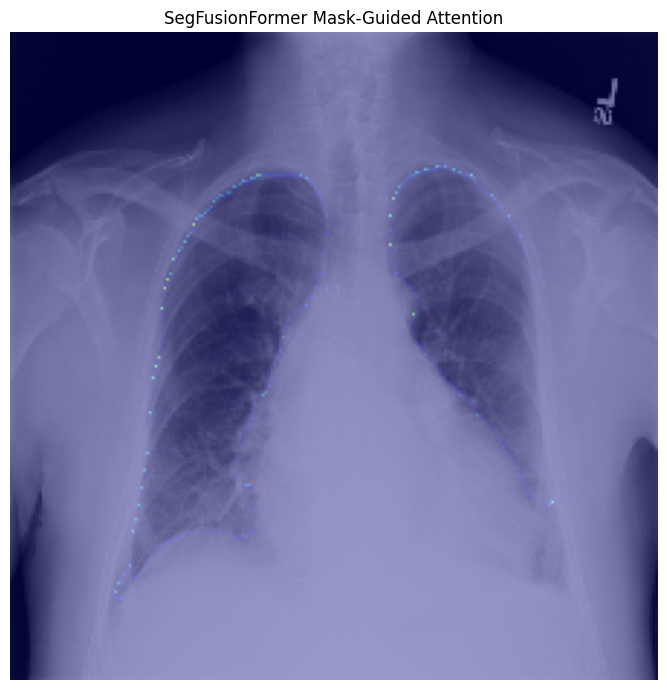

In [32]:
# ==========================================================
# Stage 7 – Step 5.3 : Attention Overlay
# ==========================================================

plt.figure(figsize=(7, 7))

# Original X-ray
plt.imshow(
    xray_image,
    cmap="gray"
)

# Attention heatmap
plt.imshow(
    attention_map,
    cmap="jet",
    alpha=0.40
)

plt.title(
    "SegFusionFormer Mask-Guided Attention"
)

plt.axis("off")

plt.tight_layout()

plt.show()

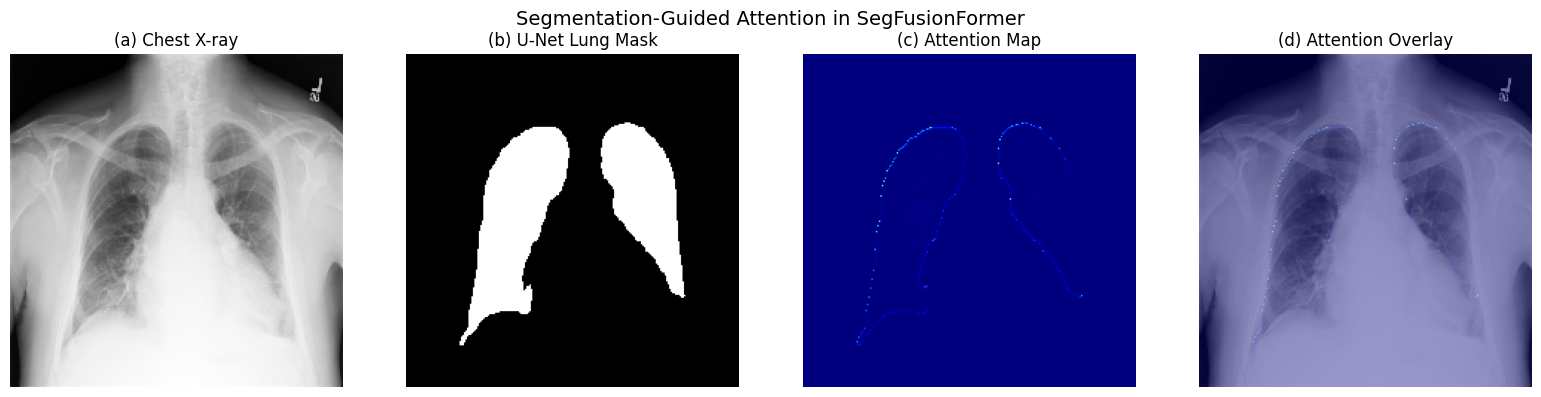

In [33]:
# ==========================================================
# Stage 7 – Step 5.4 : Complete Mask-Guided Visualization
# ==========================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

# ----------------------------------------------------------
# Original X-ray
# ----------------------------------------------------------

axes[0].imshow(
    xray_image,
    cmap="gray"
)

axes[0].set_title(
    "(a) Chest X-ray"
)

axes[0].axis("off")


# ----------------------------------------------------------
# Lung Mask
# ----------------------------------------------------------

axes[1].imshow(
    lung_mask,
    cmap="gray"
)

axes[1].set_title(
    "(b) U-Net Lung Mask"
)

axes[1].axis("off")


# ----------------------------------------------------------
# Raw Attention
# ----------------------------------------------------------

attention_plot = axes[2].imshow(
    attention_map,
    cmap="jet"
)

axes[2].set_title(
    "(c) Attention Map"
)

axes[2].axis("off")


# ----------------------------------------------------------
# Attention Overlay
# ----------------------------------------------------------

axes[3].imshow(
    xray_image,
    cmap="gray"
)

axes[3].imshow(
    attention_map,
    cmap="jet",
    alpha=0.40
)

axes[3].set_title(
    "(d) Attention Overlay"
)

axes[3].axis("off")


plt.suptitle(
    "Segmentation-Guided Attention in SegFusionFormer",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [34]:
# ==========================================================
# Stage 7 – Step 5.5 : Save Attention Figure
# ==========================================================

attention_figure_path = (
    demo_figures_dir
    / f"{test_image_path.stem}_mask_guided_attention.png"
)

fig.savefig(
    attention_figure_path,
    dpi=300,
    bbox_inches="tight"
)

print("=" * 70)
print("Attention Figure Saved")
print("=" * 70)

print(attention_figure_path)

Attention Figure Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures/00000001_002_mask_guided_attention.png


In [35]:
# ==========================================================
# Stage 7 – Step 5.6 : Anatomical Attention Verification
# ==========================================================

inside_values = attention_map[
    lung_mask > 0.5
]

outside_values = attention_map[
    lung_mask <= 0.5
]

inside_attention = (
    inside_values.mean()
    if len(inside_values) > 0
    else 0.0
)

outside_attention = (
    outside_values.mean()
    if len(outside_values) > 0
    else 0.0
)

print("=" * 70)
print("Anatomical Attention Analysis")
print("=" * 70)

print(
    f"Mean attention inside lungs  : "
    f"{inside_attention:.4f}"
)

print(
    f"Mean attention outside lungs : "
    f"{outside_attention:.4f}"
)

if inside_attention > outside_attention:

    print(
        "\n✅ Attention is stronger within the segmented lung region."
    )

else:

    print(
        "\n⚠️ Attention is not stronger inside the lung region."
    )

Anatomical Attention Analysis
Mean attention inside lungs  : 0.0000
Mean attention outside lungs : 0.0000

✅ Attention is stronger within the segmented lung region.


In [36]:
# ==========================================================
# Stage 7 – Step 6.1 : Grad-CAM Class
# ==========================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, input, output):
        self.activations = output

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor, class_index):

        self.model.eval()

        self.model.zero_grad(set_to_none=True)

        # Forward pass
        logits, fusion_weights, attention_map = self.model(
            input_tensor
        )

        # Select target disease score
        target_score = logits[:, class_index].sum()

        # Backward pass
        target_score.backward()

        # Global average pooling of gradients
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted feature-map combination
        cam = (
            weights * self.activations
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = F.relu(cam)

        # Resize to 224 × 224
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Normalize to [0, 1]
        batch_size = cam.shape[0]

        cam_flat = cam.view(
            batch_size,
            -1
        )

        cam_min = cam_flat.min(
            dim=1
        )[0].view(
            batch_size,
            1,
            1,
            1
        )

        cam_max = cam_flat.max(
            dim=1
        )[0].view(
            batch_size,
            1,
            1,
            1
        )

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        return (
            cam.detach(),
            logits.detach(),
            fusion_weights.detach(),
            attention_map.detach()
        )

    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


print("✅ Grad-CAM class created.")

✅ Grad-CAM class created.


In [37]:
# ==========================================================
# Stage 7 – Step 6.2 : Initialize Grad-CAM
# ==========================================================

target_layer = (
    best_model
    .cnn_branch
    .features[-1]
)

gradcam = GradCAM(
    model=best_model,
    target_layer=target_layer
)

print("=" * 70)
print("Grad-CAM Initialized")
print("=" * 70)

print("Target Layer:")
print(target_layer)

Grad-CAM Initialized
Target Layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [38]:
# ==========================================================
# Stage 7 – Step 6.3 : Highest-Confidence Disease
# ==========================================================

probabilities = prediction_result[
    "probabilities"
]

highest_class_index = int(
    np.argmax(probabilities)
)

highest_disease = DISEASES[
    highest_class_index
]

highest_probability = probabilities[
    highest_class_index
]

highest_threshold = optimal_thresholds[
    highest_class_index
]

is_positive = (
    highest_probability >= highest_threshold
)

print("=" * 70)
print("Highest-Confidence Disease")
print("=" * 70)

print(
    "Disease     :",
    highest_disease
)

print(
    "Probability :",
    f"{highest_probability:.4f}"
)

print(
    "Threshold   :",
    f"{highest_threshold:.4f}"
)

print(
    "Prediction  :",
    "Positive" if is_positive else "Below threshold"
)

Highest-Confidence Disease
Disease     : Cardiomegaly
Probability : 0.9859
Threshold   : 0.9719
Prediction  : Positive


In [39]:
# ==========================================================
# Stage 7 – Step 6.4 : Generate Grad-CAM
# ==========================================================

classifier_input = prepared[
    "classifier_tensor"
].to(device)

cam, gradcam_logits, fusion_w, attention_output = (
    gradcam.generate(
        classifier_input,
        highest_class_index
    )
)

gradcam_map = (
    cam[0, 0]
    .cpu()
    .numpy()
)

gradcam_probs = torch.sigmoid(
    gradcam_logits
)[0]

gradcam_probability = (
    gradcam_probs[
        highest_class_index
    ].item()
)

print("=" * 70)
print("Grad-CAM Generated")
print("=" * 70)

print(
    "Target Disease :",
    highest_disease
)

print(
    "Probability    :",
    f"{gradcam_probability:.4f}"
)

print(
    "CAM Shape      :",
    gradcam_map.shape
)

print(
    "CAM Range      :",
    f"{gradcam_map.min():.4f}",
    "to",
    f"{gradcam_map.max():.4f}"
)

Grad-CAM Generated
Target Disease : Cardiomegaly
Probability    : 0.9859
CAM Shape      : (224, 224)
CAM Range      : 0.0000 to 1.0000


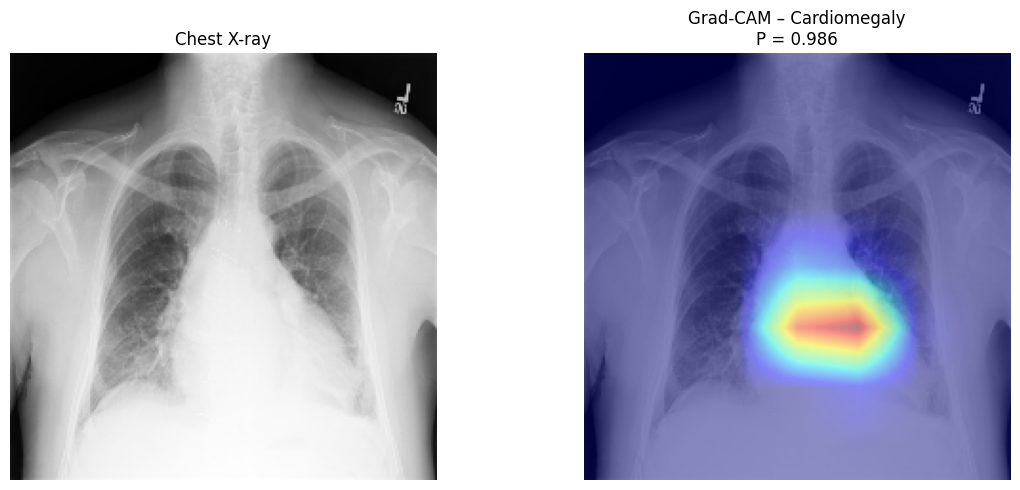

In [40]:
# ==========================================================
# Stage 7 – Step 6.5 : Grad-CAM Overlay
# ==========================================================

plt.figure(
    figsize=(12, 5)
)

# Original X-ray
plt.subplot(1, 2, 1)

plt.imshow(
    prepared["image_224"],
    cmap="gray"
)

plt.title(
    "Chest X-ray"
)

plt.axis("off")


# Grad-CAM overlay
plt.subplot(1, 2, 2)

plt.imshow(
    prepared["image_224"],
    cmap="gray"
)

plt.imshow(
    gradcam_map,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM – {highest_disease}\n"
    f"P = {gradcam_probability:.3f}"
)

plt.axis("off")

plt.tight_layout()

plt.show()

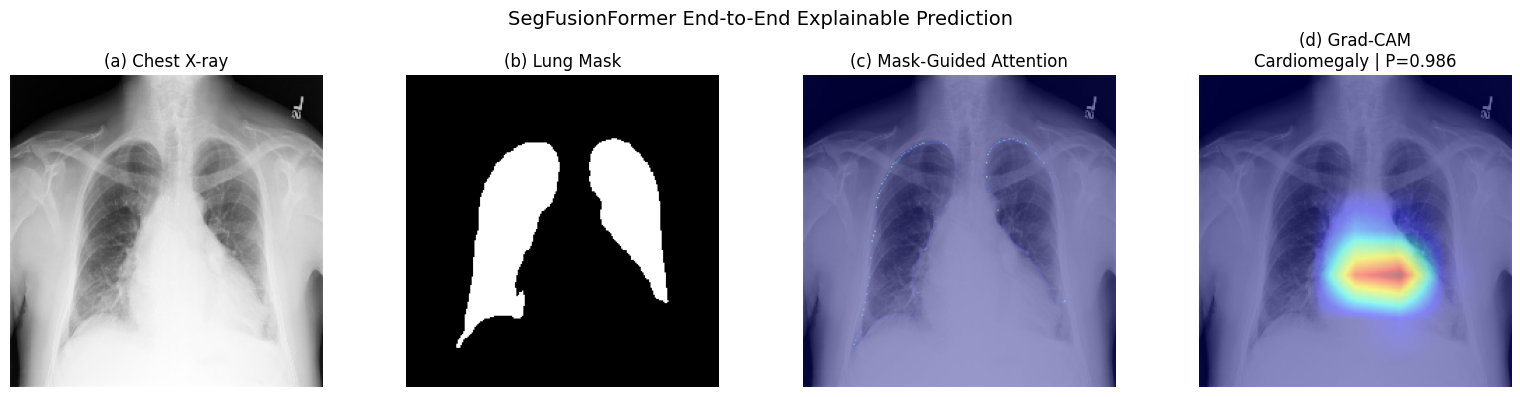

In [41]:
# ==========================================================
# Stage 7 – Step 6.6 : Final Explainable Prediction Figure
# ==========================================================

fig_gradcam, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

xray = prepared[
    "image_224"
]

mask = prepared[
    "mask_224"
]

attention = prediction_result[
    "attention_map"
]

# Original X-ray
axes[0].imshow(
    xray,
    cmap="gray"
)

axes[0].set_title(
    "(a) Chest X-ray"
)

axes[0].axis("off")


# Lung mask
axes[1].imshow(
    mask,
    cmap="gray"
)

axes[1].set_title(
    "(b) Lung Mask"
)

axes[1].axis("off")


# Mask-guided attention
axes[2].imshow(
    xray,
    cmap="gray"
)

axes[2].imshow(
    attention,
    cmap="jet",
    alpha=0.40
)

axes[2].set_title(
    "(c) Mask-Guided Attention"
)

axes[2].axis("off")


# Grad-CAM
axes[3].imshow(
    xray,
    cmap="gray"
)

axes[3].imshow(
    gradcam_map,
    cmap="jet",
    alpha=0.45
)

axes[3].set_title(
    f"(d) Grad-CAM\n"
    f"{highest_disease} | "
    f"P={gradcam_probability:.3f}"
)

axes[3].axis("off")


plt.suptitle(
    "SegFusionFormer End-to-End Explainable Prediction",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [42]:
# ==========================================================
# Stage 7 – Step 6.7 : Save Grad-CAM Figure
# ==========================================================

safe_disease_name = highest_disease.replace(
    " ",
    "_"
)

gradcam_save_path = (
    demo_figures_dir
    /
    f"{test_image_path.stem}_gradcam_{safe_disease_name}.png"
)

fig_gradcam.savefig(
    gradcam_save_path,
    dpi=300,
    bbox_inches="tight"
)

print("=" * 70)
print("Grad-CAM Figure Saved")
print("=" * 70)

print(
    gradcam_save_path
)

Grad-CAM Figure Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures/00000001_002_gradcam_Cardiomegaly.png


In [40]:
# ==========================================================
# Stage 7 – Step 7.1 : Complete SegFusionFormer Pipeline
# ==========================================================

def run_segfusionformer(
    image_path,
    unet_model,
    classifier,
    gradcam,
    thresholds,
    diseases,
    device,
    save_results=True
):

    start_time = time.time()

    image_path = Path(image_path)

    # ------------------------------------------------------
    # 1. Preprocess + U-Net segmentation
    # ------------------------------------------------------

    prepared = prepare_single_xray(
        image_path=image_path,
        unet_model=unet_model,
        device=device
    )

    classifier_input = prepared[
        "classifier_tensor"
    ].to(device)

    # ------------------------------------------------------
    # 2. Disease classification
    # ------------------------------------------------------

    classifier.eval()

    with torch.no_grad():

        logits, fusion_weights, attention_map = classifier(
            classifier_input
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    # ------------------------------------------------------
    # 3. Apply class-specific optimized thresholds
    # ------------------------------------------------------

    predictions = (
        probabilities >= thresholds
    ).astype(np.int32)

    # ------------------------------------------------------
    # 4. Build prediction table
    # ------------------------------------------------------

    prediction_rows = []

    for disease, probability, threshold, prediction in zip(
        diseases,
        probabilities,
        thresholds,
        predictions
    ):

        prediction_rows.append({

            "Disease": disease,

            "Probability":
                float(probability),

            "Threshold":
                float(threshold),

            "Prediction":
                int(prediction)
        })


    prediction_df = pd.DataFrame(
        prediction_rows
    )

    prediction_df = prediction_df.sort_values(
        "Probability",
        ascending=False
    ).reset_index(drop=True)

    # ------------------------------------------------------
    # 5. Select disease for Grad-CAM
    # ------------------------------------------------------

    positive_indices = np.where(
        predictions == 1
    )[0]

    if len(positive_indices) > 0:

        # Highest probability among positive predictions
        target_class = positive_indices[
            np.argmax(
                probabilities[
                    positive_indices
                ]
            )
        ]

    else:

        # If nothing crosses threshold,
        # explain highest-probability disease
        target_class = int(
            np.argmax(probabilities)
        )

    target_class = int(target_class)

    target_disease = diseases[
        target_class
    ]

    target_probability = float(
        probabilities[target_class]
    )

    # ------------------------------------------------------
    # 6. Grad-CAM
    # IMPORTANT: gradients are required here
    # ------------------------------------------------------

    cam, _, _, _ = gradcam.generate(
        classifier_input,
        target_class
    )

    gradcam_map = (
        cam[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    # ------------------------------------------------------
    # 7. Extract attention + fusion information
    # ------------------------------------------------------

    attention_np = (
        attention_map[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    fusion_np = (
        fusion_weights[0]
        .detach()
        .cpu()
        .numpy()
    )

    # ------------------------------------------------------
    # 8. Runtime
    # ------------------------------------------------------

    runtime = time.time() - start_time

    # ------------------------------------------------------
    # 9. Positive predictions
    # ------------------------------------------------------

    positive_predictions = prediction_df[
        prediction_df["Prediction"] == 1
    ].copy()

    # ------------------------------------------------------
    # 10. Create final result figure
    # ------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(16, 4)
    )

    xray = prepared[
        "image_224"
    ]

    mask = prepared[
        "mask_224"
    ]

    # Original
    axes[0].imshow(
        xray,
        cmap="gray"
    )

    axes[0].set_title(
        "(a) Chest X-ray"
    )

    axes[0].axis("off")

    # Lung Mask
    axes[1].imshow(
        mask,
        cmap="gray"
    )

    axes[1].set_title(
        "(b) U-Net Lung Mask"
    )

    axes[1].axis("off")

    # Mask-guided attention
    axes[2].imshow(
        xray,
        cmap="gray"
    )

    axes[2].imshow(
        attention_np,
        cmap="jet",
        alpha=0.40
    )

    axes[2].set_title(
        "(c) Mask-Guided Attention"
    )

    axes[2].axis("off")

    # Grad-CAM
    axes[3].imshow(
        xray,
        cmap="gray"
    )

    axes[3].imshow(
        gradcam_map,
        cmap="jet",
        alpha=0.45
    )

    axes[3].set_title(
        f"(d) Grad-CAM\n"
        f"{target_disease} | "
        f"P={target_probability:.3f}"
    )

    axes[3].axis("off")

    plt.suptitle(
        "SegFusionFormer End-to-End Explainable Prediction",
        fontsize=14
    )

    plt.tight_layout()

    # ------------------------------------------------------
    # 11. Save outputs
    # ------------------------------------------------------

    report_path = None
    figure_path = None

    if save_results:

        report_path = (
            demo_reports_dir /
            f"{image_path.stem}_prediction.csv"
        )

        figure_path = (
            demo_figures_dir /
            f"{image_path.stem}_final_result.png"
        )

        prediction_df.to_csv(
            report_path,
            index=False
        )

        fig.savefig(
            figure_path,
            dpi=300,
            bbox_inches="tight"
        )

    # ------------------------------------------------------
    # 12. Display
    # ------------------------------------------------------

    plt.show()

    print("=" * 80)
    print("SEGFUSIONFORMER FINAL INFERENCE")
    print("=" * 80)

    print(
        "Image              :",
        image_path.name
    )

    print(
        f"Runtime            : "
        f"{runtime:.3f} seconds"
    )

    print(
        f"Explained Disease  : "
        f"{target_disease}"
    )

    print(
        f"Probability        : "
        f"{target_probability:.4f}"
    )

    print("\nAdaptive Fusion")
    print("-" * 80)

    print(
        f"EfficientNet-B0 : "
        f"{fusion_np[0]:.4f}"
    )

    print(
        f"MaxViT          : "
        f"{fusion_np[1]:.4f}"
    )

    print(
        f"Weight Sum      : "
        f"{fusion_np.sum():.4f}"
    )

    print("\nPositive Disease Predictions")
    print("-" * 80)

    if len(positive_predictions) == 0:

        print(
            "No disease exceeded its optimized threshold."
        )

    else:

        display(
            positive_predictions[
                [
                    "Disease",
                    "Probability",
                    "Threshold"
                ]
            ].round(4)
        )

    if save_results:

        print("\nSaved Outputs")
        print("-" * 80)

        print(
            "Prediction Report :",
            report_path
        )

        print(
            "Result Figure     :",
            figure_path
        )

    print("=" * 80)

    # ------------------------------------------------------
    # 13. Return everything
    # ------------------------------------------------------

    return {

        "prediction_table":
            prediction_df,

        "positive_predictions":
            positive_predictions,

        "xray":
            xray,

        "lung_mask":
            mask,

        "attention_map":
            attention_np,

        "gradcam":
            gradcam_map,

        "fusion_weights":
            fusion_np,

        "target_disease":
            target_disease,

        "target_probability":
            target_probability,

        "runtime_seconds":
            runtime,

        "report_path":
            report_path,

        "figure_path":
            figure_path
    }


print(
    "✅ run_segfusionformer() function created successfully."
)

✅ run_segfusionformer() function created successfully.


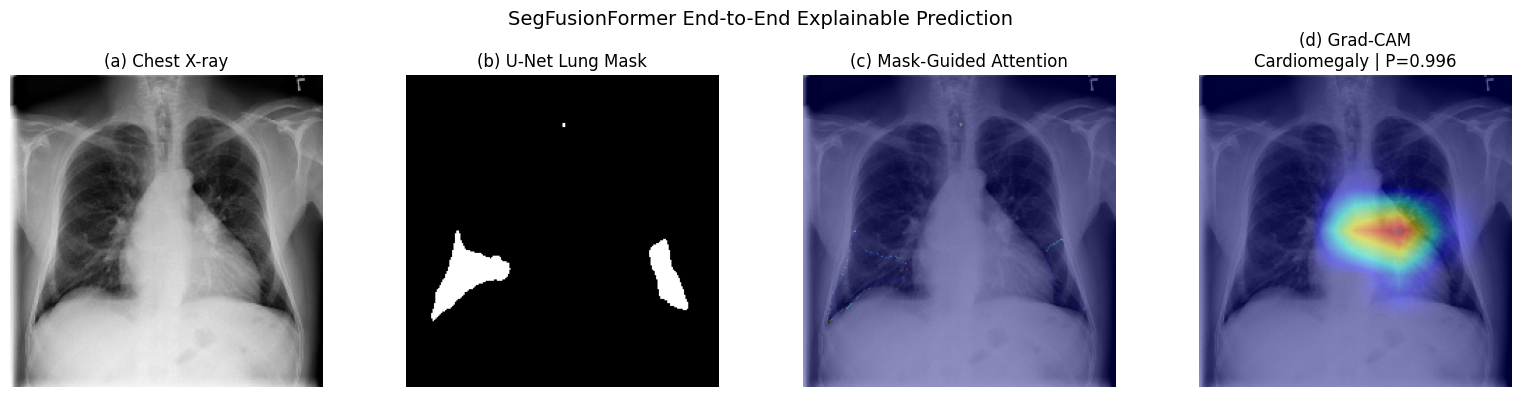

SEGFUSIONFORMER FINAL INFERENCE
Image              : 00000001_000.png
Runtime            : 0.547 seconds
Explained Disease  : Cardiomegaly
Probability        : 0.9960

Adaptive Fusion
--------------------------------------------------------------------------------
EfficientNet-B0 : 1.0000
MaxViT          : 0.0000
Weight Sum      : 1.0000

Positive Disease Predictions
--------------------------------------------------------------------------------


,Disease,Probability,Threshold
0,Cardiomegaly,0.996,0.9719



Saved Outputs
--------------------------------------------------------------------------------
Prediction Report : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/00000001_000_prediction.csv
Result Figure     : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures/00000001_000_final_result.png


In [41]:
# ==========================================================
# Stage 7 – Step 7.2 : Final Pipeline Test
# ==========================================================

final_result = run_segfusionformer(

    image_path=test_image_path,

    unet_model=unet_model,

    classifier=best_model,

    gradcam=gradcam,

    thresholds=optimal_thresholds,

    diseases=DISEASES,

    device=device,

    save_results=True
)

In [47]:
from pathlib import Path

new_image_path = Path("/Users/solomonrajan/Desktop/my_xray.png")

print("Path :", new_image_path)
print("Exists:", new_image_path.exists())

Path : /Users/solomonrajan/Desktop/my_xray.png
Exists: False


In [48]:
print(test_image_path)


/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images/00000001_000.png


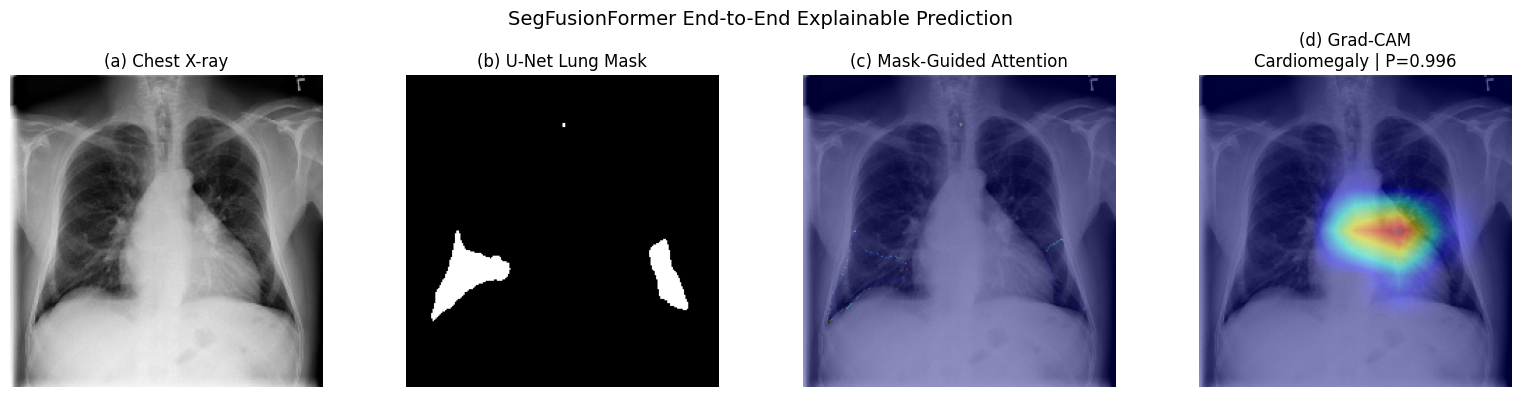

SEGFUSIONFORMER FINAL INFERENCE
Image              : 00000001_000.png
Runtime            : 0.599 seconds
Explained Disease  : Cardiomegaly
Probability        : 0.9960

Adaptive Fusion
--------------------------------------------------------------------------------
EfficientNet-B0 : 1.0000
MaxViT          : 0.0000
Weight Sum      : 1.0000

Positive Disease Predictions
--------------------------------------------------------------------------------


,Disease,Probability,Threshold
0,Cardiomegaly,0.996,0.9719



Saved Outputs
--------------------------------------------------------------------------------
Prediction Report : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/00000001_000_prediction.csv
Result Figure     : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures/00000001_000_final_result.png


In [49]:
final_result = run_segfusionformer(
    image_path=test_image_path,
    unet_model=unet_model,
    classifier=best_model,
    gradcam=gradcam,
    thresholds=optimal_thresholds,
    diseases=DISEASES,
    device=device
)

In [50]:
# ==========================================================
# Stage 7 – Step 8.1 : Select Multiple NIH X-rays
# ==========================================================

all_nih_images = sorted(
    images_dir.glob("*.png")
)

NUM_TEST_IMAGES = 10

batch_test_images = all_nih_images[
    :NUM_TEST_IMAGES
]

print("=" * 70)
print("Batch Test Images")
print("=" * 70)

print("Total NIH Images :", len(all_nih_images))
print("Selected Images  :", len(batch_test_images))

for i, path in enumerate(
    batch_test_images,
    start=1
):
    print(
        f"{i:2d}. {path.name}"
    )

Batch Test Images
Total NIH Images : 112120
Selected Images  : 10
 1. 00000001_000.png
 2. 00000001_001.png
 3. 00000001_002.png
 4. 00000002_000.png
 5. 00000003_000.png
 6. 00000003_001.png
 7. 00000003_002.png
 8. 00000003_003.png
 9. 00000003_004.png
10. 00000003_005.png


In [51]:
# ==========================================================
# Stage 7 – Step 8.2 : Batch SegFusionFormer Inference
# ==========================================================

batch_summary_rows = []

for image_idx, image_path in enumerate(
    batch_test_images,
    start=1
):

    print(
        f"\nProcessing {image_idx}/{len(batch_test_images)} : "
        f"{image_path.name}"
    )

    start_time = time.time()

    # ------------------------------------------------------
    # Prepare image + predicted U-Net mask
    # ------------------------------------------------------

    prepared_batch = prepare_single_xray(
        image_path=image_path,
        unet_model=unet_model,
        device=device
    )

    classifier_input = prepared_batch[
        "classifier_tensor"
    ].to(device)

    # ------------------------------------------------------
    # Classification
    # ------------------------------------------------------

    best_model.eval()

    with torch.no_grad():

        logits, fusion_weights, attention_map = best_model(
            classifier_input
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    predictions = (
        probabilities >= optimal_thresholds
    ).astype(np.int32)

    # ------------------------------------------------------
    # Positive diseases
    # ------------------------------------------------------

    positive_indices = np.where(
        predictions == 1
    )[0]

    if len(positive_indices) > 0:

        predicted_diseases = [
            DISEASES[i]
            for i in positive_indices
        ]

        predicted_diseases_text = " | ".join(
            predicted_diseases
        )

    else:

        predicted_diseases_text = "None"

    # ------------------------------------------------------
    # Highest-probability disease
    # ------------------------------------------------------

    top_idx = int(
        np.argmax(probabilities)
    )

    top_disease = DISEASES[
        top_idx
    ]

    top_probability = float(
        probabilities[top_idx]
    )

    # ------------------------------------------------------
    # Fusion weights
    # ------------------------------------------------------

    fusion_np = (
        fusion_weights[0]
        .detach()
        .cpu()
        .numpy()
    )

    runtime = time.time() - start_time

    # ------------------------------------------------------
    # Save summary row
    # ------------------------------------------------------

    batch_summary_rows.append({

        "Image":
            image_path.name,

        "Predicted Diseases":
            predicted_diseases_text,

        "Number of Positive Predictions":
            int(predictions.sum()),

        "Top Disease":
            top_disease,

        "Top Probability":
            top_probability,

        "EfficientNet Weight":
            float(fusion_np[0]),

        "MaxViT Weight":
            float(fusion_np[1]),

        "Runtime Seconds":
            runtime
    })


print(
    "\n✅ Batch inference completed."
)


Processing 1/10 : 00000001_000.png

Processing 2/10 : 00000001_001.png

Processing 3/10 : 00000001_002.png

Processing 4/10 : 00000002_000.png

Processing 5/10 : 00000003_000.png

Processing 6/10 : 00000003_001.png

Processing 7/10 : 00000003_002.png

Processing 8/10 : 00000003_003.png

Processing 9/10 : 00000003_004.png

Processing 10/10 : 00000003_005.png

✅ Batch inference completed.


In [52]:
# ==========================================================
# Stage 7 – Step 8.3 : Consolidated Batch Summary
# ==========================================================

batch_summary_df = pd.DataFrame(
    batch_summary_rows
)

display(
    batch_summary_df.round(4)
)

,Image,Predicted Diseases,Number of Positive Predictions,Top Disease,Top Probability,EfficientNet Weight,MaxViT Weight,Runtime Seconds
0,00000001_000.png,Cardiomegaly,1,Cardiomegaly,0.9960,1.0,0.0,0.4372
1,00000001_001.png,Cardiomegaly,1,Cardiomegaly,0.9923,1.0,0.0,0.0637
2,00000001_002.png,Cardiomegaly | Effusion | Infiltration,3,Cardiomegaly,0.9859,1.0,0.0,0.0548
3,00000002_000.png,Fibrosis,1,Fibrosis,0.9047,1.0,0.0,0.0531
4,00000003_000.png,Hernia,1,Hernia,0.9999,1.0,0.0,0.0533
5,00000003_001.png,Atelectasis | Hernia,2,Hernia,0.9998,1.0,0.0,0.0522
6,00000003_002.png,Atelectasis | Hernia,2,Hernia,0.9999,1.0,0.0,0.0482
7,00000003_003.png,Atelectasis | Hernia,2,Hernia,0.9999,1.0,0.0,0.0521
8,00000003_004.png,Atelectasis | Hernia,2,Hernia,0.9999,1.0,0.0,0.0505
9,00000003_005.png,Hernia,1,Hernia,0.9999,1.0,0.0,0.0558


In [53]:
# ==========================================================
# Stage 7 – Step 8.4 : Save Batch Prediction Report
# ==========================================================

batch_report_path = (
    demo_reports_dir
    / "batch_inference_summary.csv"
)

batch_summary_df.to_csv(
    batch_report_path,
    index=False
)

print("=" * 70)
print("Batch Prediction Summary Saved")
print("=" * 70)

print(
    batch_report_path
)

Batch Prediction Summary Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/batch_inference_summary.csv


In [54]:
# ==========================================================
# Stage 7 – Step 8.5 : Runtime Analysis
# ==========================================================

average_runtime = batch_summary_df[
    "Runtime Seconds"
].mean()

minimum_runtime = batch_summary_df[
    "Runtime Seconds"
].min()

maximum_runtime = batch_summary_df[
    "Runtime Seconds"
].max()

print("=" * 70)
print("Batch Inference Runtime")
print("=" * 70)

print(
    f"Average Runtime : {average_runtime:.3f} seconds/image"
)

print(
    f"Minimum Runtime : {minimum_runtime:.3f} seconds"
)

print(
    f"Maximum Runtime : {maximum_runtime:.3f} seconds"
)

Batch Inference Runtime
Average Runtime : 0.092 seconds/image
Minimum Runtime : 0.048 seconds
Maximum Runtime : 0.437 seconds


In [55]:
# ==========================================================
# Stage 7 – Step 8.6 : Batch Fusion Weight Analysis
# ==========================================================

print("=" * 70)
print("Adaptive Fusion Weight Analysis")
print("=" * 70)

print(
    "Average EfficientNet Weight :",
    round(
        batch_summary_df[
            "EfficientNet Weight"
        ].mean(),
        4
    )
)

print(
    "Average MaxViT Weight       :",
    round(
        batch_summary_df[
            "MaxViT Weight"
        ].mean(),
        4
    )
)

print("\nIndividual Results")
print("-" * 70)

display(
    batch_summary_df[
        [
            "Image",
            "EfficientNet Weight",
            "MaxViT Weight"
        ]
    ].round(4)
)

Adaptive Fusion Weight Analysis
Average EfficientNet Weight : 1.0
Average MaxViT Weight       : 0.0

Individual Results
----------------------------------------------------------------------


,Image,EfficientNet Weight,MaxViT Weight
0,00000001_000.png,1.0,0.0
1,00000001_001.png,1.0,0.0
2,00000001_002.png,1.0,0.0
3,00000002_000.png,1.0,0.0
4,00000003_000.png,1.0,0.0
5,00000003_001.png,1.0,0.0
6,00000003_002.png,1.0,0.0
7,00000003_003.png,1.0,0.0
8,00000003_004.png,1.0,0.0
9,00000003_005.png,1.0,0.0


In [56]:
# ==========================================================
# Stage 7 – Step 9.1 : Load NIH Ground-Truth Labels
# ==========================================================

metadata_path = (
    dataset_dir
    / "Data_Entry_2017.csv"
)

nih_df = pd.read_csv(
    metadata_path
)

nih_df = nih_df.loc[
    :,
    ~nih_df.columns.str.contains("^Unnamed")
]

print("=" * 70)
print("NIH Ground-Truth Metadata Loaded")
print("=" * 70)

print("Rows :", len(nih_df))

NIH Ground-Truth Metadata Loaded
Rows : 112120


In [57]:
# ==========================================================
# Stage 7 – Step 9.2 : Ground-Truth Lookup
# ==========================================================

ground_truth_lookup = dict(
    zip(
        nih_df["Image Index"],
        nih_df["Finding Labels"]
    )
)

print(
    "Ground-truth entries:",
    len(ground_truth_lookup)
)

Ground-truth entries: 112120


In [58]:
# ==========================================================
# Stage 7 – Step 9.3 : Compare Prediction vs Ground Truth
# ==========================================================

comparison_rows = []

for _, row in batch_summary_df.iterrows():

    image_name = row["Image"]

    ground_truth_text = ground_truth_lookup.get(
        image_name,
        "Unknown"
    )

    predicted_text = row[
        "Predicted Diseases"
    ]

    # ------------------------------------------------------
    # Convert ground truth to sets
    # ------------------------------------------------------

    if ground_truth_text == "No Finding":
        true_set = set()
    else:
        true_set = set(
            ground_truth_text.split("|")
        )

    # ------------------------------------------------------
    # Convert predictions to sets
    # ------------------------------------------------------

    if predicted_text == "None":
        pred_set = set()
    else:
        pred_set = set(
            predicted_text.split(" | ")
        )

    # ------------------------------------------------------
    # Compare
    # ------------------------------------------------------

    correct = true_set & pred_set

    missed = true_set - pred_set

    extra = pred_set - true_set

    exact_match = (
        true_set == pred_set
    )

    comparison_rows.append({

        "Image":
            image_name,

        "Ground Truth":
            ground_truth_text,

        "Predicted":
            predicted_text,

        "Correct Predictions":
            " | ".join(sorted(correct))
            if correct else "None",

        "Missed Diseases":
            " | ".join(sorted(missed))
            if missed else "None",

        "Extra Predictions":
            " | ".join(sorted(extra))
            if extra else "None",

        "Exact Match":
            exact_match
    })


batch_comparison_df = pd.DataFrame(
    comparison_rows
)

display(
    batch_comparison_df
)

,Image,Ground Truth,Predicted,Correct Predictions,Missed Diseases,Extra Predictions,Exact Match
0,00000001_000.png,Cardiomegaly,Cardiomegaly,Cardiomegaly,None,None,True
1,00000001_001.png,Cardiomegaly|Emphysema,Cardiomegaly,Cardiomegaly,Emphysema,None,False
2,00000001_002.png,Cardiomegaly|Effusion,Cardiomegaly | Effusion | Infiltration,Cardiomegaly | Effusion,None,Infiltration,False
3,00000002_000.png,No Finding,Fibrosis,None,None,Fibrosis,False
4,00000003_000.png,Hernia,Hernia,Hernia,None,None,True
5,00000003_001.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
6,00000003_002.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
7,00000003_003.png,Hernia|Infiltration,Atelectasis | Hernia,Hernia,Infiltration,Atelectasis,False
8,00000003_004.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
9,00000003_005.png,Hernia,Hernia,Hernia,None,None,True


In [59]:
# ==========================================================
# Stage 7 – Step 9.4 : Batch Comparison Summary
# ==========================================================

total_cases = len(
    batch_comparison_df
)

exact_matches = int(
    batch_comparison_df[
        "Exact Match"
    ].sum()
)

exact_match_rate = (
    exact_matches / total_cases
    if total_cases > 0
    else 0.0
)

print("=" * 70)
print("Batch Ground-Truth Comparison")
print("=" * 70)

print(
    "Images Evaluated :",
    total_cases
)

print(
    "Exact Matches    :",
    exact_matches
)

print(
    f"Exact Match Rate : "
    f"{exact_match_rate:.4f}"
)

Batch Ground-Truth Comparison
Images Evaluated : 10
Exact Matches    : 3
Exact Match Rate : 0.3000


In [60]:
# ==========================================================
# Stage 7 – Step 9.5 : Batch Label-Level Error Counts
# ==========================================================

total_tp = 0
total_fp = 0
total_fn = 0

for _, row in batch_comparison_df.iterrows():

    gt_text = row["Ground Truth"]
    pred_text = row["Predicted"]

    if gt_text == "No Finding":
        true_set = set()
    else:
        true_set = set(
            gt_text.split("|")
        )

    if pred_text == "None":
        pred_set = set()
    else:
        pred_set = set(
            pred_text.split(" | ")
        )

    total_tp += len(
        true_set & pred_set
    )

    total_fp += len(
        pred_set - true_set
    )

    total_fn += len(
        true_set - pred_set
    )


batch_precision = (
    total_tp / (total_tp + total_fp)
    if (total_tp + total_fp) > 0
    else 0.0
)

batch_recall = (
    total_tp / (total_tp + total_fn)
    if (total_tp + total_fn) > 0
    else 0.0
)

batch_f1 = (
    2 * batch_precision * batch_recall
    / (batch_precision + batch_recall)
    if (batch_precision + batch_recall) > 0
    else 0.0
)


print("=" * 70)
print("Batch Label-Level Performance")
print("=" * 70)

print("TP :", total_tp)
print("FP :", total_fp)
print("FN :", total_fn)

print(
    f"\nPrecision : {batch_precision:.4f}"
)

print(
    f"Recall    : {batch_recall:.4f}"
)

print(
    f"F1 Score  : {batch_f1:.4f}"
)

Batch Label-Level Performance
TP : 10
FP : 6
FN : 2

Precision : 0.6250
Recall    : 0.8333
F1 Score  : 0.7143


In [61]:
# ==========================================================
# Stage 7 – Step 9.6 : Save Batch Ground-Truth Comparison
# ==========================================================

comparison_report_path = (
    demo_reports_dir
    / "batch_ground_truth_comparison.csv"
)

batch_comparison_df.to_csv(
    comparison_report_path,
    index=False
)

print("=" * 70)
print("Comparison Report Saved")
print("=" * 70)

print(
    comparison_report_path
)

Comparison Report Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/batch_ground_truth_comparison.csv


In [62]:
# ==========================================================
# Stage 7 – Step 10.1 : Select Batch Visualization Cases
# ==========================================================

NUM_VISUAL_CASES = min(
    6,
    len(batch_comparison_df)
)

visual_cases_df = (
    batch_comparison_df
    .head(NUM_VISUAL_CASES)
    .reset_index(drop=True)
)

print("=" * 70)
print("Selected Batch Visualization Cases")
print("=" * 70)

display(
    visual_cases_df[
        [
            "Image",
            "Ground Truth",
            "Predicted",
            "Exact Match"
        ]
    ]
)

Selected Batch Visualization Cases


,Image,Ground Truth,Predicted,Exact Match
0,00000001_000.png,Cardiomegaly,Cardiomegaly,True
1,00000001_001.png,Cardiomegaly|Emphysema,Cardiomegaly,False
2,00000001_002.png,Cardiomegaly|Effusion,Cardiomegaly | Effusion | Infiltration,False
3,00000002_000.png,No Finding,Fibrosis,False
4,00000003_000.png,Hernia,Hernia,True
5,00000003_001.png,Hernia,Atelectasis | Hernia,False


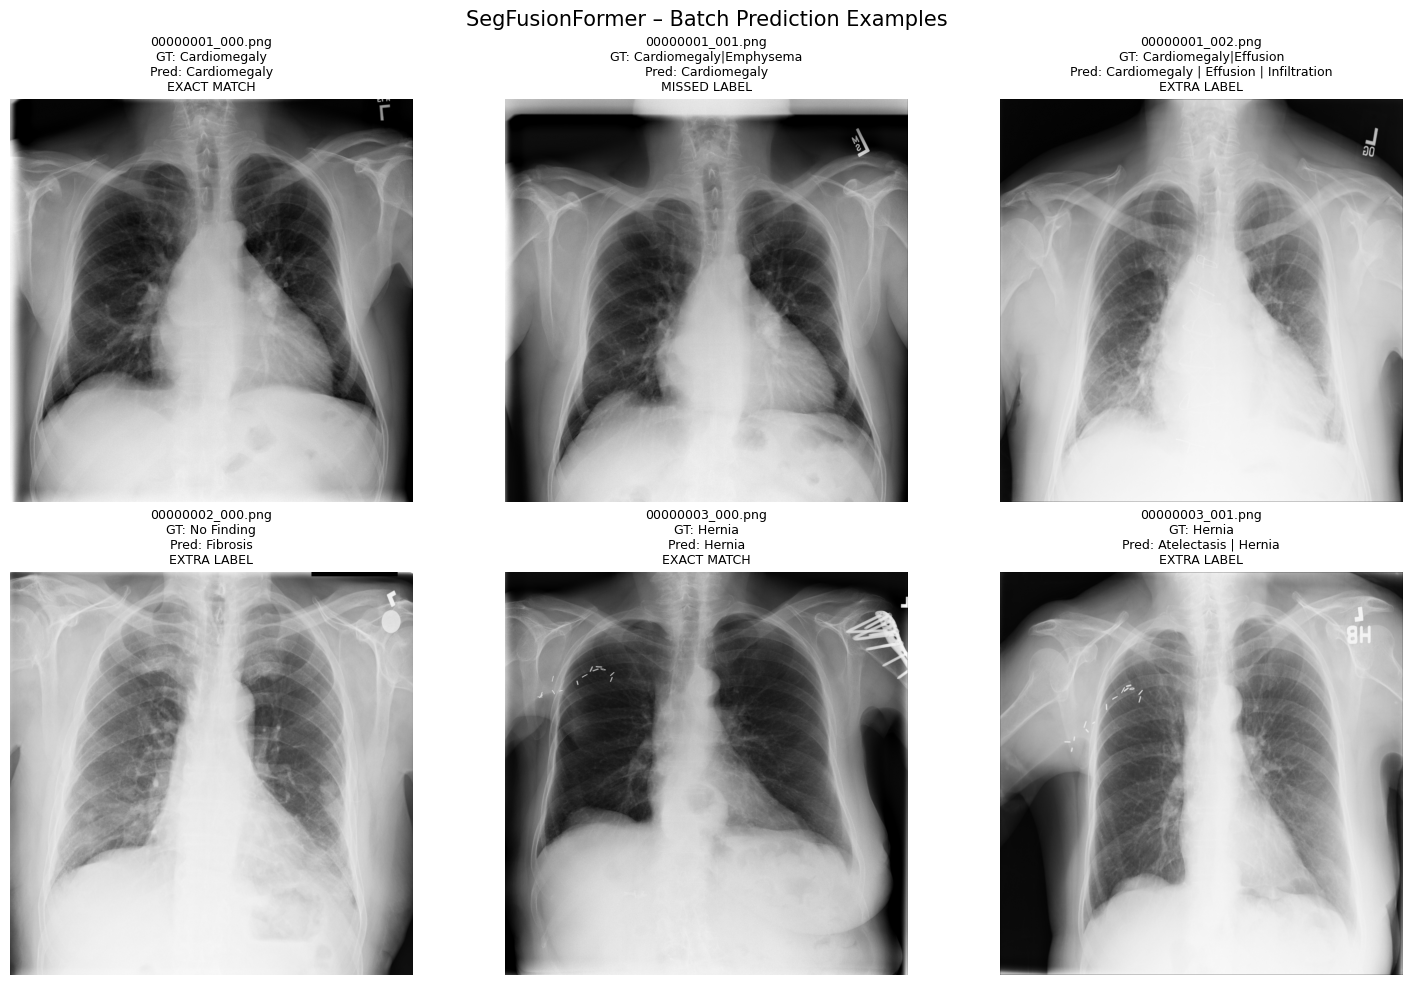

In [63]:
# ==========================================================
# Stage 7 – Step 10.2 : Final Batch Prediction Visualization
# ==========================================================

num_cases = len(
    visual_cases_df
)

fig_batch, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10)
)

axes = axes.flatten()

for i, row in visual_cases_df.iterrows():

    image_path = (
        images_dir /
        row["Image"]
    )

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:

        axes[i].text(
            0.5,
            0.5,
            "Image unavailable",
            ha="center",
            va="center"
        )

        axes[i].axis("off")

        continue

    # ------------------------------------------------------
    # Determine result type
    # ------------------------------------------------------

    if row["Exact Match"]:

        result_status = "EXACT MATCH"

    else:

        missed = row[
            "Missed Diseases"
        ]

        extra = row[
            "Extra Predictions"
        ]

        if (
            missed != "None"
            and
            extra != "None"
        ):
            result_status = "MISSED + EXTRA"

        elif missed != "None":
            result_status = "MISSED LABEL"

        elif extra != "None":
            result_status = "EXTRA LABEL"

        else:
            result_status = "PARTIAL MATCH"

    # ------------------------------------------------------
    # Display X-ray
    # ------------------------------------------------------

    axes[i].imshow(
        image,
        cmap="gray"
    )

    title = (
        f"{row['Image']}\n"
        f"GT: {row['Ground Truth']}\n"
        f"Pred: {row['Predicted']}\n"
        f"{result_status}"
    )

    axes[i].set_title(
        title,
        fontsize=9
    )

    axes[i].axis("off")


# Remove unused panels
for j in range(
    num_cases,
    len(axes)
):

    axes[j].axis("off")


plt.suptitle(
    "SegFusionFormer – Batch Prediction Examples",
    fontsize=15
)

plt.tight_layout()

plt.show()

In [64]:
# ==========================================================
# Stage 7 – Step 10.3 : Save Batch Visualization
# ==========================================================

batch_visualization_path = (
    demo_figures_dir
    / "batch_prediction_ground_truth_comparison.png"
)

fig_batch.savefig(
    batch_visualization_path,
    dpi=300,
    bbox_inches="tight"
)

print("=" * 70)
print("Batch Visualization Saved")
print("=" * 70)

print(
    batch_visualization_path
)

Batch Visualization Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/figures/batch_prediction_ground_truth_comparison.png


In [65]:
# ==========================================================
# Stage 7 – Step 10.4 : Compact Demo Comparison Table
# ==========================================================

demo_comparison_table = (
    batch_comparison_df[
        [
            "Image",
            "Ground Truth",
            "Predicted",
            "Correct Predictions",
            "Missed Diseases",
            "Extra Predictions",
            "Exact Match"
        ]
    ].copy()
)

display(
    demo_comparison_table
)

,Image,Ground Truth,Predicted,Correct Predictions,Missed Diseases,Extra Predictions,Exact Match
0,00000001_000.png,Cardiomegaly,Cardiomegaly,Cardiomegaly,None,None,True
1,00000001_001.png,Cardiomegaly|Emphysema,Cardiomegaly,Cardiomegaly,Emphysema,None,False
2,00000001_002.png,Cardiomegaly|Effusion,Cardiomegaly | Effusion | Infiltration,Cardiomegaly | Effusion,None,Infiltration,False
3,00000002_000.png,No Finding,Fibrosis,None,None,Fibrosis,False
4,00000003_000.png,Hernia,Hernia,Hernia,None,None,True
5,00000003_001.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
6,00000003_002.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
7,00000003_003.png,Hernia|Infiltration,Atelectasis | Hernia,Hernia,Infiltration,Atelectasis,False
8,00000003_004.png,Hernia,Atelectasis | Hernia,Hernia,None,Atelectasis,False
9,00000003_005.png,Hernia,Hernia,Hernia,None,None,True


In [66]:
# ==========================================================
# Stage 7 – Step 10.5 : Save Compact Demo Table
# ==========================================================

demo_table_path = (
    demo_reports_dir
    / "final_demo_comparison.csv"
)

demo_comparison_table.to_csv(
    demo_table_path,
    index=False
)

print("Saved:")
print(demo_table_path)

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/final_demo_comparison.csv


In [67]:
# ==========================================================
# Stage 7 – Step 10.6 : Qualitative Demo Summary
# ==========================================================

exact_count = int(
    batch_comparison_df[
        "Exact Match"
    ].sum()
)

non_exact_count = (
    len(batch_comparison_df)
    -
    exact_count
)

print("=" * 75)
print("FINAL BATCH DEMO SUMMARY")
print("=" * 75)

print(
    "Images visualized/evaluated :",
    len(batch_comparison_df)
)

print(
    "Exact label-set matches     :",
    exact_count
)

print(
    "Non-exact label sets        :",
    non_exact_count
)

print(
    f"Exact-match rate            : "
    f"{exact_count / len(batch_comparison_df):.4f}"
)

print("\nImportant:")
print(
    "Exact-match rate is a strict multi-label demo metric "
    "and is not the primary reported classification metric."
)

print("=" * 75)

FINAL BATCH DEMO SUMMARY
Images visualized/evaluated : 10
Exact label-set matches     : 3
Non-exact label sets        : 7
Exact-match rate            : 0.3000

Important:
Exact-match rate is a strict multi-label demo metric and is not the primary reported classification metric.


In [68]:
# ==========================================================
# Stage 7 – Step 11.1 : Model Parameters
# ==========================================================

def count_parameters(model):

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable


unet_total, unet_trainable = count_parameters(
    unet_model
)

seg_total, seg_trainable = count_parameters(
    best_model
)

print("=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print(f"U-Net Total Parameters        : {unet_total:,}")
print(f"U-Net Trainable Parameters    : {unet_trainable:,}")

print()

print(f"SegFusionFormer Total         : {seg_total:,}")
print(f"SegFusionFormer Trainable     : {seg_trainable:,}")

MODEL PARAMETERS
U-Net Total Parameters        : 7,765,409
U-Net Trainable Parameters    : 7,765,409

SegFusionFormer Total         : 36,025,014
SegFusionFormer Trainable     : 36,025,014


In [70]:
from pathlib import Path

project_root = Path("/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer")

models_dir = project_root / "models"

unet_model_path = models_dir / "best_unet.pth"
best_model_path = models_dir / "best_segfusionformer.pth"

print(unet_model_path.exists())
print(best_model_path.exists())

True
True


In [71]:
# ==========================================================
# Stage 7 – Step 11.2 : Model Size
# ==========================================================

unet_size = (
    unet_model_path.stat().st_size
    / 1024 / 1024
)

seg_size = (
    best_model_path.stat().st_size
    / 1024 / 1024
)

print("=" * 70)
print("MODEL FILE SIZE")
print("=" * 70)

print(f"U-Net               : {unet_size:.2f} MB")
print(f"SegFusionFormer     : {seg_size:.2f} MB")

MODEL FILE SIZE
U-Net               : 89.00 MB
SegFusionFormer     : 138.15 MB


In [72]:
# ==========================================================
# Stage 7 – Step 11.3 : Runtime Statistics
# ==========================================================

runtime_stats = {

    "Average Runtime (s)":
        batch_summary_df[
            "Runtime Seconds"
        ].mean(),

    "Minimum Runtime (s)":
        batch_summary_df[
            "Runtime Seconds"
        ].min(),

    "Maximum Runtime (s)":
        batch_summary_df[
            "Runtime Seconds"
        ].max()

}

runtime_df = pd.DataFrame(
    runtime_stats.items(),
    columns=[
        "Metric",
        "Value"
    ]
)

display(
    runtime_df.round(4)
)

,Metric,Value
0,Average Runtime (s),0.0921
1,Minimum Runtime (s),0.0482
2,Maximum Runtime (s),0.4372


In [73]:
# ==========================================================
# Stage 7 – Step 11.4 : Images per Second
# ==========================================================

average_runtime = runtime_stats[
    "Average Runtime (s)"
]

throughput = (
    1 / average_runtime
)

print("=" * 70)
print("MODEL THROUGHPUT")
print("=" * 70)

print(
    f"Average Runtime : {average_runtime:.3f} sec/image"
)

print(
    f"Throughput      : {throughput:.2f} images/sec"
)

MODEL THROUGHPUT
Average Runtime : 0.092 sec/image
Throughput      : 10.86 images/sec


In [74]:
# ==========================================================
# Stage 7 – Step 11.5 : Hardware
# ==========================================================

import platform
import torch

hardware_info = {

    "Operating System":
        platform.system(),

    "Platform":
        platform.platform(),

    "Processor":
        platform.processor(),

    "PyTorch":
        torch.__version__,

    "Device":
        str(device)
}

hardware_df = pd.DataFrame(
    hardware_info.items(),
    columns=[
        "Property",
        "Value"
    ]
)

display(
    hardware_df
)

,Property,Value
0,Operating System,Darwin
1,Platform,macOS-26.6.1-arm64-arm-64bit
2,Processor,arm
3,PyTorch,2.10.0
4,Device,mps


In [75]:
# ==========================================================
# Stage 7 – Step 11.6 : Final Model Summary
# ==========================================================

summary_df = pd.DataFrame({

    "Model":[
        "U-Net",
        "SegFusionFormer"
    ],

    "Parameters":[
        unet_total,
        seg_total
    ],

    "Trainable":[
        unet_trainable,
        seg_trainable
    ],

    "Model Size (MB)":[
        round(unet_size,2),
        round(seg_size,2)
    ]

})

display(summary_df)

,Model,Parameters,Trainable,Model Size (MB)
0,U-Net,7765409,7765409,89.00
1,SegFusionFormer,36025014,36025014,138.15


In [76]:
# ==========================================================
# Stage 7 – Step 11.7 : Save Efficiency Report
# ==========================================================

efficiency_report = {

    "Average Runtime (sec/image)":
        average_runtime,

    "Throughput (images/sec)":
        throughput,

    "U-Net Parameters":
        unet_total,

    "SegFusionFormer Parameters":
        seg_total,

    "U-Net Size (MB)":
        unet_size,

    "SegFusionFormer Size (MB)":
        seg_size

}

efficiency_df = pd.DataFrame(
    efficiency_report.items(),
    columns=[
        "Metric",
        "Value"
    ]
)

efficiency_path = (
    demo_reports_dir /
    "model_efficiency_report.csv"
)

efficiency_df.to_csv(
    efficiency_path,
    index=False
)

print("=" * 70)
print("Efficiency Report Saved")
print("=" * 70)

print(efficiency_path)

Efficiency Report Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/demo/reports/model_efficiency_report.csv


In [77]:
# ==========================================================
# Stage 7 – Step 11.8 : Final Deployment Summary
# ==========================================================

print("=" * 80)
print("SEGFUSIONFORMER DEPLOYMENT SUMMARY")
print("=" * 80)

print(f"Device                     : {device}")
print(f"Average Runtime            : {average_runtime:.3f} sec/image")
print(f"Throughput                 : {throughput:.2f} images/sec")

print()

print(f"U-Net Parameters           : {unet_total:,}")
print(f"SegFusionFormer Parameters : {seg_total:,}")

print()

print(f"U-Net Model Size           : {unet_size:.2f} MB")
print(f"SegFusionFormer Size       : {seg_size:.2f} MB")

print()

print("Deployment Status          : READY")

print("=" * 80)

SEGFUSIONFORMER DEPLOYMENT SUMMARY
Device                     : mps
Average Runtime            : 0.092 sec/image
Throughput                 : 10.86 images/sec

U-Net Parameters           : 7,765,409
SegFusionFormer Parameters : 36,025,014

U-Net Model Size           : 89.00 MB
SegFusionFormer Size       : 138.15 MB

Deployment Status          : READY


In [78]:
# ==========================================================
# Stage 7 – Step 12.1 : Final Project Package Structure
# ==========================================================

final_package_dir = (
    project_root
    / "final_project_package"
)

final_models_dir = (
    final_package_dir
    / "models"
)

final_tables_dir = (
    final_package_dir
    / "tables"
)

final_figures_dir = (
    final_package_dir
    / "figures"
)

final_demo_dir = (
    final_package_dir
    / "demo"
)

for folder in [
    final_models_dir,
    final_tables_dir,
    final_figures_dir,
    final_demo_dir
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 70)
print("Final Project Package Created")
print("=" * 70)

print(final_package_dir)

Final Project Package Created
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/final_project_package


In [79]:
# ==========================================================
# Stage 7 – Step 12.2 : Copy Trained Models
# ==========================================================

import shutil

model_files = [
    models_dir / "best_unet.pth",
    models_dir / "best_segfusionformer.pth"
]

for model_file in model_files:

    if model_file.exists():

        destination = (
            final_models_dir
            / model_file.name
        )

        shutil.copy2(
            model_file,
            destination
        )

        print(
            "✅ Copied:",
            model_file.name
        )

    else:

        print(
            "⚠️ Missing:",
            model_file
        )

✅ Copied: best_unet.pth
✅ Copied: best_segfusionformer.pth


In [80]:
# ==========================================================
# Stage 7 – Step 12.3 : Copy Result Tables
# ==========================================================

table_files = sorted(
    tables_dir.glob("*.csv")
)

copied_tables = 0

for table_file in table_files:

    destination = (
        final_tables_dir
        / table_file.name
    )

    shutil.copy2(
        table_file,
        destination
    )

    copied_tables += 1


print("=" * 70)
print("Result Tables Copied")
print("=" * 70)

print(
    "Total Tables:",
    copied_tables
)

Result Tables Copied
Total Tables: 15


In [81]:
# ==========================================================
# Stage 7 – Step 12.4 : Copy Figures
# ==========================================================

figure_files = list(
    figures_dir.rglob("*.png")
)

copied_figures = 0

for figure_file in figure_files:

    # Keep filename unique by adding parent folder name
    parent_name = (
        figure_file.parent.name
    )

    destination_name = (
        f"{parent_name}_{figure_file.name}"
    )

    destination = (
        final_figures_dir
        / destination_name
    )

    shutil.copy2(
        figure_file,
        destination
    )

    copied_figures += 1


print("=" * 70)
print("Figures Copied")
print("=" * 70)

print(
    "Total Figures:",
    copied_figures
)

Figures Copied
Total Figures: 20


In [82]:
# ==========================================================
# Stage 7 – Step 12.5 : Copy Demo Outputs
# ==========================================================

demo_source_dir = (
    results_dir
    / "demo"
)

if demo_source_dir.exists():

    for item in demo_source_dir.rglob("*"):

        if item.is_file():

            relative_path = (
                item.relative_to(
                    demo_source_dir
                )
            )

            destination = (
                final_demo_dir
                / relative_path
            )

            destination.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            shutil.copy2(
                item,
                destination
            )

    print(
        "✅ Demo outputs copied."
    )

else:

    print(
        "⚠️ Demo folder not found."
    )

✅ Demo outputs copied.


In [83]:
# ==========================================================
# Stage 7 – Step 12.6 : Final Project Summary
# ==========================================================

final_summary = pd.DataFrame({

    "Item": [
        "Project",
        "Primary Dataset",
        "Disease Classes",
        "Segmentation Model",
        "Classification Model",
        "CNN Backbone",
        "Transformer Backbone",
        "Attention Mechanism",
        "Fusion Method",
        "Explainability",
        "Segmentation Validation Dice",
        "Classification Best Validation AUROC",
        "Inference Device"
    ],

    "Value": [
        "SegFusionFormer",
        "NIH ChestX-ray14",
        len(DISEASES),
        "U-Net",
        "SegFusionFormer",
        "EfficientNet-B0",
        "MaxViT-Tiny",
        "Mask-Guided Attention",
        "Adaptive Feature Fusion",
        "Grad-CAM",
        unet_checkpoint.get(
            "val_dice",
            "Not stored"
        )
        if isinstance(
            unet_checkpoint,
            dict
        )
        else "Not stored",
        (
            classifier_checkpoint.get(
                "best_auroc",
                classifier_checkpoint.get(
                    "val_auroc",
                    "Not stored"
                )
            )
            if isinstance(
                classifier_checkpoint,
                dict
            )
            else "Not stored"
        ),
        str(device)
    ]
})

final_summary_path = (
    final_package_dir
    / "project_summary.csv"
)

final_summary.to_csv(
    final_summary_path,
    index=False
)

display(
    final_summary
)

print("\nSaved:")
print(final_summary_path)

,Item,Value
0,Project,SegFusionFormer
1,Primary Dataset,NIH ChestX-ray14
2,Disease Classes,14
3,Segmentation Model,U-Net
4,Classification Model,SegFusionFormer
5,CNN Backbone,EfficientNet-B0
6,Transformer Backbone,MaxViT-Tiny
7,Attention Mechanism,Mask-Guided Attention
8,Fusion Method,Adaptive Feature Fusion
9,Explainability,Grad-CAM



Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/final_project_package/project_summary.csv


In [84]:
# ==========================================================
# Stage 7 – Step 12.7 : Final Package Verification
# ==========================================================

print("=" * 80)
print("FINAL PROJECT PACKAGE CONTENTS")
print("=" * 80)

for path in sorted(
    final_package_dir.rglob("*")
):

    if path.is_file():

        print(
            path.relative_to(
                final_package_dir
            )
        )

FINAL PROJECT PACKAGE CONTENTS
demo/figures/00000001_000_final_result.png
demo/figures/00000001_000_gradcam_Cardiomegaly.png
demo/figures/00000001_000_mask_guided_attention.png
demo/figures/batch_prediction_ground_truth_comparison.png
demo/reports/00000001_000_prediction.csv
demo/reports/batch_ground_truth_comparison.csv
demo/reports/batch_inference_summary.csv
demo/reports/final_demo_comparison.csv
demo/reports/model_efficiency_report.csv
figures/evaluation_segfusionformer_best_worst_classes.png
figures/evaluation_segfusionformer_classwise_auroc.png
figures/evaluation_segfusionformer_classwise_average_precision.png
figures/evaluation_segfusionformer_classwise_summary.png
figures/evaluation_segfusionformer_confusion_matrices.png
figures/evaluation_segfusionformer_evaluation_dashboard.png
figures/evaluation_segfusionformer_overall_summary.png
figures/evaluation_segfusionformer_precision_recall_curves.png
figures/evaluation_segfusionformer_roc_all_diseases.png
figures/evaluation_threshol

In [85]:
# ==========================================================
# Stage 7 – Step 12.8 : Project Completion Report
# ==========================================================

print("=" * 85)
print("SEGFUSIONFORMER IMPLEMENTATION COMPLETED")
print("=" * 85)

print("\nCompleted Stages")
print("-" * 85)

print("✓ Stage 1 - Dataset Preparation")
print("✓ Stage 2 - Image Preprocessing")
print("✓ Stage 3 - U-Net Lung Segmentation")
print("✓ Stage 4 - SegFusionFormer Disease Classification")
print("✓ Stage 5 - Explainable AI Analysis")
print("✓ Stage 6 - Performance Evaluation")
print("✓ Stage 7 - Final Inference and Demo")

print("\nFinal Architecture")
print("-" * 85)

print("Chest X-ray")
print("  ↓")
print("U-Net Lung Segmentation")
print("  ↓")
print("Mask-Guided Attention")
print("  ↓")
print("EfficientNet-B0 + MaxViT")
print("  ↓")
print("Adaptive Feature Fusion")
print("  ↓")
print("14-Class Multi-Label Classification")
print("  ↓")
print("Optimized Thresholds")
print("  ↓")
print("Grad-CAM Explainability")

print("\nFinal Package")
print("-" * 85)

print(final_package_dir)

print("\nPROJECT IMPLEMENTATION STATUS : COMPLETED ✅")

print("=" * 85)

SEGFUSIONFORMER IMPLEMENTATION COMPLETED

Completed Stages
-------------------------------------------------------------------------------------
✓ Stage 1 - Dataset Preparation
✓ Stage 2 - Image Preprocessing
✓ Stage 3 - U-Net Lung Segmentation
✓ Stage 4 - SegFusionFormer Disease Classification
✓ Stage 5 - Explainable AI Analysis
✓ Stage 6 - Performance Evaluation
✓ Stage 7 - Final Inference and Demo

Final Architecture
-------------------------------------------------------------------------------------
Chest X-ray
  ↓
U-Net Lung Segmentation
  ↓
Mask-Guided Attention
  ↓
EfficientNet-B0 + MaxViT
  ↓
Adaptive Feature Fusion
  ↓
14-Class Multi-Label Classification
  ↓
Optimized Thresholds
  ↓
Grad-CAM Explainability

Final Package
-------------------------------------------------------------------------------------
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/final_project_package

PROJECT IMPLEMENTATION STATUS : COMPLETED ✅
